In [ ]:
  from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Projects/karate-kumite-performance-profiles-lab/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Projects/karate-kumite-performance-profiles-lab


In [ ]:
import os
print("CPU cores (os.cpu_count):", os.cpu_count())
!nproc
!lscpu | grep -E "^CPU\(s\)|Thread\(s\) per core|Core\(s\) per socket|Model name"
!free -h

CPU cores (os.cpu_count): 8
8
CPU(s):                                  8
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Thread(s) per core:                      2
Core(s) per socket:                      4
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.8Gi        46Gi       2.2Mi       3.5Gi        49Gi
Swap:             0B          0B          0B


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
)

RNG_SEED = 0
np.random.seed(RNG_SEED)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "Female-42kg": DATA_DIR / "female_42kg.csv",
    "Female-47kg": DATA_DIR / "female_47kg.csv",
    "Female-54kg": DATA_DIR / "female_54kg.csv",
}

P0_FEATURES = ["yuko", "waza_ari", "ippon", "attack", "defend",
               "longest_point_in_sec", "fastest_point_in_sec"]

TIMING_FEATURES    = ["longest_point_in_sec", "fastest_point_in_sec"]
NONTIMING_FEATURES = [c for c in P0_FEATURES if c not in TIMING_FEATURES]

S1_FEATURES = P0_FEATURES + ["match_attack", "match_defend"]
S2_FEATURES = P0_FEATURES + ["state_numeric", "hantei", "point_diff"]
STRUCTURAL_ZERO_FEATURES = ["yuko", "longest_point_in_sec", "fastest_point_in_sec"]


In [ ]:
# @title Timing utilities (every step's run time is appended to outputs/timing_log.csv)
import os, time
from contextlib import contextmanager

TIMING_FILE = OUTPUT_DIR / "timing_log.csv"
TIMING_COLUMNS = ["timestamp", "session", "step", "weight_class", "method", "config",
                  "n_items", "seconds", "cpu_seconds", "n_cores"]
SESSION_ID = pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S")   # one id per notebook run

def log_time(step, seconds, cpu_seconds=np.nan, weight_class="", method="", config="", n_items=1):
    row = {"timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"), "session": SESSION_ID,
           "step": step, "weight_class": weight_class, "method": method, "config": config,
           "n_items": n_items, "seconds": round(float(seconds), 3),
           "cpu_seconds": round(float(cpu_seconds), 3), "n_cores": os.cpu_count()}
    pd.DataFrame([row], columns=TIMING_COLUMNS).to_csv(
        TIMING_FILE, mode="a", header=not TIMING_FILE.exists(), index=False)

@contextmanager
def timed(step, **meta):
    """with timed("P0 selection", weight_class=wc, method="Ward"): ..."""
    t0, c0 = time.perf_counter(), time.process_time()
    yield
    log_time(step, time.perf_counter() - t0, time.process_time() - c0, **meta)

print("Timing log:", TIMING_FILE, "| session", SESSION_ID)

Timing log: outputs/timing_log.csv | session 2026-10-07 04:55:55


#Data

In [ ]:
# @title [function]-Load Data
# Load data function

def _synthetic_weight_class(seed, n_matches=19):

    rng = np.random.default_rng(seed)
    n = n_matches * 2
    m = np.repeat(np.arange(n_matches), 2)
    df = pd.DataFrame({
        "weight_class": "Female-Demo",
        "stage": "stage-1",
        "match": m,
        "name": [f"athlete_{i}" for i in range(n)],
        "state": rng.choice(["win", "lose"], size=n),
        "hantei": 0,
        "yuko": rng.poisson(1.2, size=n) * rng.choice([0, 1], size=n, p=[0.4, 0.6]),
        "waza_ari": rng.poisson(0.2, size=n),
        "ippon": rng.poisson(0.1, size=n),
        "attack": rng.poisson(8, size=n),
        "defend": rng.poisson(6, size=n),
        "longest_point_in_sec": rng.uniform(0, 90, size=n) * rng.choice([0, 1], size=n, p=[0.3, 0.7]),
        "fastest_point_in_sec": rng.uniform(0, 40, size=n) * rng.choice([0, 1], size=n, p=[0.3, 0.7]),
        "match_attack": rng.poisson(16, size=n),
        "match_defend": rng.poisson(12, size=n),
        "point_diff": rng.integers(-8, 8, size=n),
    })
    return df


def load_weight_class(name, filepath):
    if filepath.exists():
        df = pd.read_csv(filepath, sep=";")
        df = df.dropna(how="all").reset_index(drop=True)
        df.columns = df.columns.str.strip()
    else:
        print(f"[demo mode] {filepath} not found -- using synthetic stand-in for {name}")
        df = _synthetic_weight_class(seed=hash(name) % (2**31))
    df["state_numeric"] = df["state"].str.lower().map({"win": 1, "lose": 0})
    return df

In [ ]:
# @title [implementation]-Load Data
raw_data = {name: load_weight_class(name, path) for name, path in FILES.items()}

for name, df in raw_data.items():
  print("Data: ", name, " with ", df.shape[0], " samples and ", df.shape[1], " features")

print("")
print("Features: ")
for cfg_name, feats in [("P0", P0_FEATURES), ("S1", S1_FEATURES), ("S2", S2_FEATURES)]:
  print(cfg_name, ": ", feats)

print("")
print("Samples [P0 features only]: ")
display(raw_data["Female-42kg"][["name"] + P0_FEATURES].head(3))

Data:  Female-42kg  with  38  samples and  21  features
Data:  Female-47kg  with  38  samples and  21  features
Data:  Female-54kg  with  38  samples and  21  features

Features: 
P0 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec']
S1 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec', 'match_attack', 'match_defend']
S2 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec', 'state_numeric', 'hantei', 'point_diff']

Samples [P0 features only]: 


,name,yuko,waza_ari,ippon,attack,defend,longest_point_in_sec,fastest_point_in_sec
0,S. Mosleh,2,0,2,4,2,6,2
1,Vinogradova,0,0,0,4,1,0,0
2,Abellanosa,0,0,0,2,4,0,0


## EDA on P0 Feature

In [ ]:
display(raw_data["Female-42kg"][P0_FEATURES].describe())
#display(raw_data["Female-47kg"][P0_FEATURES].describe())
#display(raw_data["Female-54kg"][P0_FEATURES].describe())

,yuko,waza_ari,ippon,attack,defend,longest_point_in_sec,fastest_point_in_sec
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,2.684211,0.105263,0.315789,5.500000,3.552632,3.631579,2.078947
std,2.692384,0.311012,0.701553,2.152936,1.781244,3.026201,1.666548
min,0.000000,0.000000,0.000000,2.000000,1.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,4.000000,2.000000,0.000000,0.000000
50%,2.500000,0.000000,0.000000,5.000000,3.500000,5.000000,3.000000
75%,4.750000,0.000000,0.000000,6.000000,5.000000,6.000000,3.000000
max,9.000000,1.000000,2.000000,11.000000,7.000000,8.000000,4.000000


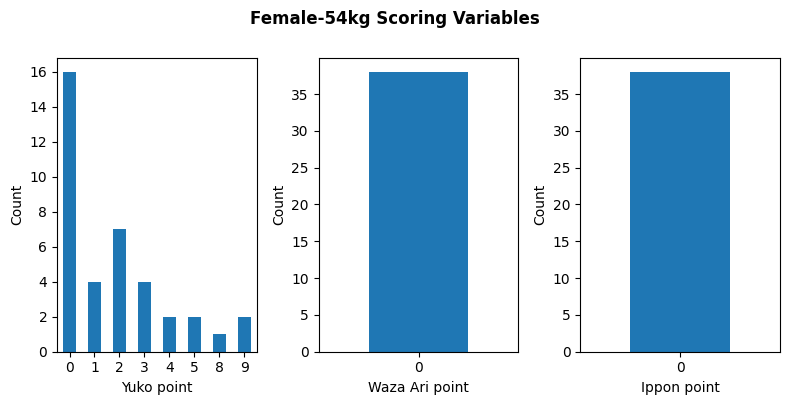

In [ ]:
# @title Scoring Variables Distribution { run: "auto" }
# @markdown Here the distribution of Scoring Variables for certain weight class (wc):

wc = "Female-54kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(8, 4))
fig.suptitle(wc+" Scoring Variables", fontsize=12, fontweight='bold', y=1)

yuko_distribution = raw_data[wc][P0_FEATURES].yuko.value_counts().sort_index()
yuko_distribution.plot(kind="bar", rot=0, ax=axes[0])

axes[0].set_xlabel("Yuko point")
axes[0].set_ylabel("Count")

waza_ari_distribution = raw_data[wc][P0_FEATURES].waza_ari.value_counts().sort_index()
waza_ari_distribution.plot(kind="bar", rot=0, ax=axes[1])

axes[1].set_xlabel("Waza Ari point")
axes[1].set_ylabel("Count")

ippon_distribution = raw_data[wc][P0_FEATURES].ippon.value_counts().sort_index()
ippon_distribution.plot(kind="bar", rot=0, ax=axes[2])

axes[2].set_xlabel("Ippon point")
axes[2].set_ylabel("Count")

plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

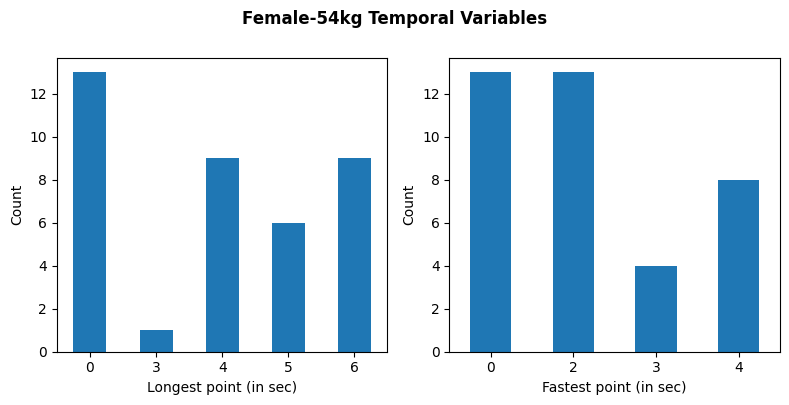

In [ ]:
# @title Temporal Variables Distribution { run: "auto" }
# @markdown Here the distribution of Temporal/Timing Variables for certain weight class (wc):

# 1. Simple text input box
wc = "Female-54kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(8, 4))
fig.suptitle(wc+" Temporal Variables", fontsize=12, fontweight='bold', y=1)

long_point_distribution = raw_data[wc][P0_FEATURES].longest_point_in_sec.value_counts().sort_index()
long_point_distribution.plot(kind="bar", rot=0, ax=axes[0])

axes[0].set_ylabel("Count")
axes[0].set_xlabel("Longest point (in sec)")

fast_point_distribution = raw_data[wc][P0_FEATURES].fastest_point_in_sec.value_counts().sort_index()
fast_point_distribution.plot(kind="bar", rot=0, ax=axes[1])

axes[1].set_xlabel("Fastest point (in sec)")
axes[1].set_ylabel("Count")

plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

#Pre-processing

##Feature Selection

In [ ]:
# @title
def build_matrix(df, feature_list):
    X_raw     = df[feature_list].apply(pd.to_numeric, errors="raise")
    variances = X_raw.var(ddof=0)
    zero_var  = variances[variances == 0].index.tolist()
    retained  = [c for c in feature_list if c not in zero_var]
    X_final   = X_raw[retained]
    scaler    = StandardScaler()
    X_scaled  = scaler.fit_transform(X_final)
    return X_scaled, retained, zero_var

In [ ]:
def build_two_part_matrix(df):
    """
    Two-part encoding of the timing variables:
      Part 1: timing_event = 1 if a scoring-time event was recorded, else 0
      Part 2: each timing variable z-scored using SCORERS ONLY;
              non-scorers set to 0 (= the average scorer)
    Zero-variance removal is reused from build_matrix().
    """
    timing = df[TIMING_FEATURES].apply(pd.to_numeric, errors="raise")
    scored = (timing > 0).any(axis=1).to_numpy()

    # Part 1: non-timing features + event indicator (goes through build_matrix)
    df_tmp = df.copy()
    df_tmp["timing_event"] = scored.astype(float)
    X_part1, retained, dropped = build_matrix(
        df_tmp, NONTIMING_FEATURES + ["timing_event"]
    )

    # Part 2: conditional durations
    cond_cols, cond_names = [], []
    for c in TIMING_FEATURES:
        s = timing.loc[scored, c]
        if s.std(ddof=0) == 0:              # constant among scorers -> drop
            dropped.append(c + "_cond")
            continue
        z = ((timing[c] - s.mean()) / s.std(ddof=0)).to_numpy(dtype=float, copy=True)
        z[~scored] = 0.0
        cond_cols.append(z)
        cond_names.append(c + "_cond")

    X_scaled = np.column_stack([X_part1] + cond_cols)
    return X_scaled, retained + cond_names, dropped

In [ ]:
prepared = {}
for wc, df in raw_data.items():
    prepared[wc] = {}
    scored   = (df[TIMING_FEATURES] > 0).any(axis=1).to_numpy()
    all_rows = np.ones(len(df), dtype=bool)

    # Original configurations
    for cfg_name, feats in [("P0", P0_FEATURES), ("S1", S1_FEATURES), ("S2", S2_FEATURES)]:
        Xs, retained, dropped = build_matrix(df, feats)
        prepared[wc][cfg_name] = {"X": Xs, "features": retained, "dropped": dropped, "rows": all_rows}
        print(wc, cfg_name, "->", Xs.shape, "dropped:", dropped)

    # TP: two-part encoding
    Xs, retained, dropped = build_two_part_matrix(df)
    prepared[wc]["TP"] = {"X": Xs, "features": retained, "dropped": dropped, "rows": all_rows}
    print(wc, "TP", "->", Xs.shape, "dropped:", dropped)

    # NT: no timing variables
    Xs, retained, dropped = build_matrix(df, NONTIMING_FEATURES)
    prepared[wc]["NT"] = {"X": Xs, "features": retained, "dropped": dropped, "rows": all_rows}
    print(wc, "NT", "->", Xs.shape, "dropped:", dropped)

    # SO: scorers only (fewer rows)
    df_so = df.loc[scored].reset_index(drop=True)
    Xs, retained, dropped = build_matrix(df_so, P0_FEATURES)
    prepared[wc]["SO"] = {"X": Xs, "features": retained, "dropped": dropped, "rows": scored}
    print(wc, "SO", "->", Xs.shape, "dropped:", dropped)
    print("")

Female-42kg P0 -> (38, 7) dropped: []
Female-42kg S1 -> (38, 9) dropped: []
Female-42kg S2 -> (38, 10) dropped: []
Female-42kg TP -> (38, 8) dropped: []
Female-42kg NT -> (38, 5) dropped: []
Female-42kg SO -> (24, 7) dropped: []

Female-47kg P0 -> (38, 7) dropped: []
Female-47kg S1 -> (38, 9) dropped: []
Female-47kg S2 -> (38, 9) dropped: ['hantei']
Female-47kg TP -> (38, 8) dropped: []
Female-47kg NT -> (38, 5) dropped: []
Female-47kg SO -> (29, 7) dropped: []

Female-54kg P0 -> (38, 5) dropped: ['waza_ari', 'ippon']
Female-54kg S1 -> (38, 7) dropped: ['waza_ari', 'ippon']
Female-54kg S2 -> (38, 8) dropped: ['waza_ari', 'ippon']
Female-54kg TP -> (38, 6) dropped: ['waza_ari', 'ippon']
Female-54kg NT -> (38, 3) dropped: ['waza_ari', 'ippon']
Female-54kg SO -> (25, 5) dropped: ['waza_ari', 'ippon']



In [ ]:
prepared["Female-54kg"]["P0"]["X"][:5]

array([[-0.78830535,  1.8384123 , -0.30567432, -1.31892584, -1.21706925],
       [-0.78830535, -1.19896454, -1.67221836, -1.31892584, -1.21706925],
       [-0.78830535, -2.41391528,  0.3775977 ,  1.1259123 ,  0.76501496],
       [ 2.45013826,  1.8384123 , -1.67221836, -0.09650677,  0.10432022],
       [-0.78830535, -0.59148917, -0.30567432, -1.31892584, -1.21706925]])

#Shared metrics, admissibility, and the selection protocol

##Constant

In [ ]:
K_VALUES = [2, 3, 4, 5]
MIN_CLUSTER_SIZE = 4

KMEANS_SEEDS = list(range(100))
KMEANS_N_INIT = 20
RSKC_SEEDS = list(range(100))
ARSK_SEEDS = list(range(100))
STOF_CONTAMINATION_PERCENT = 2.0

DBSCAN_EPS_VALUES = np.round(np.arange(0.3, 4.01, 0.1), 1)
DBSCAN_MINPTS_VALUES = [4, 5, 6]
DBSCAN_MIN_RETENTION = 0.80
EPS_NUM = 1e-12

##Metrics

In [ ]:
def cluster_sizes(labels, ignore_noise=False):
    vals, counts = np.unique(labels, return_counts=True)
    if ignore_noise:
        keep = vals != -1
        vals, counts = vals[keep], counts[keep]
    return dict(zip(vals.tolist(), counts.tolist()))


def min_cluster_size(labels, ignore_noise=False):
    sizes = cluster_sizes(labels, ignore_noise=ignore_noise)
    return min(sizes.values()) if sizes else 0


def safe_metrics(X, labels, ignore_noise=False):
    """
    The safe_metrics function won't crash on a degenerate partition

    scikit-learn's silhouette_score and davies_bouldin_score raise an error
    if the labels contain fewer than 2 distinct clusters.
    """

    mask = labels != -1 if ignore_noise else np.ones(len(labels), dtype=bool)
    Xu, lu = X[mask], labels[mask]
    if len(set(lu)) < 2:
        return np.nan, np.nan
    return silhouette_score(Xu, lu), davies_bouldin_score(Xu, lu)


def wcss_bcss_ratio(X, labels):
    mask = labels != -1
    Xu, lu = X[mask], labels[mask]
    grand_mean = Xu.mean(axis=0)
    wcss, bcss = 0.0, 0.0
    for c in np.unique(lu):
        pts = Xu[lu == c]
        cm = pts.mean(axis=0)
        wcss += ((pts - cm) ** 2).sum()
        bcss += len(pts) * ((cm - grand_mean) ** 2).sum()
    return wcss / bcss if bcss > EPS_NUM else np.nan


##Addmisible: Ward's Hierarchical Clustering

In [ ]:
def fit_ward_all_k(X, k_values=K_VALUES, min_size=MIN_CLUSTER_SIZE):
    Z = linkage(X, method="ward", metric="euclidean")
    candidates = []
    for k in k_values:
        labels = fcluster(Z, t=k, criterion="maxclust") - 1
        sil, dbi = safe_metrics(X, labels)
        admissible = (len(set(labels)) == k and min_cluster_size(labels) >= min_size
                      and not np.isnan(sil))
        candidates.append({"k": k, "labels": labels, "silhouette": sil, "dbi": dbi,
                            "wcss_bcss": wcss_bcss_ratio(X, labels), "admissible": admissible})
    adm = [c for c in candidates if c["admissible"]]
    if not adm:
        return None, candidates
    return max(adm, key=lambda c: c["silhouette"]), candidates


## Addmisible: k-Means, RSKC k-Means, and ARSK k-Means

In [ ]:
def select_representative_run(admissible_runs, target_median_silhouette):
    """
    Final partition = admissible run whose silhouette is CLOSEST TO THE
    (LOWER) MEDIAN admissible silhouette for that k (not the maximum).
    Ties -> lower DBI, then lower WCSS/BCSS, then lower seed.
    """
    tmp = admissible_runs.copy()
    tmp["distance_to_median"] = np.abs(tmp["silhouette"] - target_median_silhouette)
    tmp = tmp.sort_values(
        by=["distance_to_median", "dbi", "wcss_bcss", "seed"],
        ascending=[True, True, True, True],
    )
    return tmp.iloc[0]


def fit_across_seeds(X, fit_one_fn, seeds, k_values=K_VALUES, min_size=MIN_CLUSTER_SIZE):
    """
    Generic seed/parameter sweep + median-silhouette selection.
    Used IDENTICALLY for k-Means, RSKC-STOF, and ARSK so all three
    "seeded" methods are held to the same protocol.
    fit_one_fn(X, k, seed) -> integer label array
    """

    runs = []
    for k in k_values:
        for seed in seeds:
            labels = fit_one_fn(X, k, seed)
            sil, dbi = safe_metrics(X, labels)
            admissible = (
                len(set(labels)) == k
                and min_cluster_size(labels) >= min_size
                and not np.isnan(sil)
            )
            runs.append({"k": k, "seed": seed, "labels": labels, "silhouette": sil,
                         "dbi": dbi, "wcss_bcss": wcss_bcss_ratio(X, labels),
                         "admissible": admissible})
    runs_df = pd.DataFrame(runs)

    selected_per_k = {}
    for k in k_values:
        adm = runs_df[(runs_df.k == k) & (runs_df.admissible)]
        if len(adm) == 0:
            continue
        # Lower median: an OBSERVED silhouette value. With an even number of
        # runs, the ordinary median is the midpoint of two runs, both equally
        # close to it, and floating-point noise decides which is chosen.
        target = np.sort(adm["silhouette"].to_numpy())[(len(adm) - 1) // 2]
        selected_per_k[k] = select_representative_run(adm, target)
    if not selected_per_k:
        return None, runs_df

    best_k = max(selected_per_k, key=lambda kk: selected_per_k[kk]["silhouette"])
    return selected_per_k[best_k], runs_df


###k-Means

In [ ]:
def kmeans_once_wrapper(X, k, seed):
    return KMeans(n_clusters=k, n_init=KMEANS_N_INIT, random_state=seed).fit_predict(X)

### RSKC-STOF

Robust Sparse k-Means Clustering against STOF observations
(Madjoukeng, Kenmogne & Frénay, 2025, *IJDSA* 20:6973–6983).
Independent re-implementation of Algorithms 1–3 of the paper
(the authors' repository was not publicly accessible):
RKAS initialisation, leave-one-out ESD STOF detection per cluster and
feature (98th percentile, p = 2%), sparse weights with ‖w‖₂ = 1 and
‖w‖₁ ≤ s computed without STOF values. STOF observations are **kept**.
Sparsity bound *s* is chosen once per k by the permutation gap statistic
(Witten & Tibshirani, 2010), which the paper does not specify.

In [ ]:
# ============================================================
# ROBUST SPARSE CLUSTERING METHODS
#   1. RSKC-STOF  (Madjoukeng, Kenmogne & Frenay, 2025, IJDSA)
#   2. ARSK       (Li, Sugasawa & Katayama, 2024, TMLR)
#
# Both are independent re-implementations from the published
# algorithms (the authors' code repositories were not publicly
# accessible). Choices not specified in the papers are marked
# "[UNSPECIFIED IN PAPER]".
#
# Both plug into fit_across_seeds(X, fn, seeds) through a factory:
#     fit_across_seeds(X, make_rskc_wrapper(X), RSKC_SEEDS)
#     fit_across_seeds(X, make_arsk_wrapper(X), ARSK_SEEDS)
# The factory tunes the sparsity/robustness parameters ONCE per k
# (not once per seed) and caches them.
# ============================================================

import numpy as np
from sklearn.cluster import kmeans_plusplus

EPS_NUM = 1e-12


# ============================================================
# Shared helpers
# ============================================================

def bcss_per_feature(X, labels):
    """Between-cluster sum of squares for each feature (TSS - WSS)."""
    X = np.asarray(X, float)
    tss = ((X - X.mean(axis=0)) ** 2).sum(axis=0)
    wss = np.zeros(X.shape[1])
    for c in np.unique(labels):
        m = labels == c
        wss += ((X[m] - X[m].mean(axis=0)) ** 2).sum(axis=0)
    return np.maximum(tss - wss, 0.0)


def weighted_lloyd(X, k, weights, centers, max_iter=300, tol=1e-4):
    """
    k-Means with weighted squared distance sum_j w_j (x_j - z_j)^2.
    Equivalent to running k-Means on features multiplied by sqrt(w_j).
    Starts from the given centers.
    """
    X = np.asarray(X, float)
    centers = np.asarray(centers, float).copy()
    prev = None
    for _ in range(max_iter):
        d2 = (weights[None, None, :] * (X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = d2.argmin(axis=1)

        # Empty cluster -> re-seed with the point farthest from its center
        missing = [c for c in range(k) if c not in set(labels)]
        if missing:
            far = d2.min(axis=1).copy()
            for c in missing:
                i = int(far.argmax())
                centers[c] = X[i]
                far[i] = -np.inf
            d2 = (weights[None, None, :] * (X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
            labels = d2.argmin(axis=1)

        new = centers.copy()
        for c in range(k):
            if (labels == c).any():
                new[c] = X[labels == c].mean(axis=0)
        shift = np.linalg.norm(new - centers)
        centers = new
        if (prev is not None and np.array_equal(labels, prev)) or shift < tol:
            break
        prev = labels.copy()
    return labels, centers


# ============================================================
# 1. RSKC-STOF
# ============================================================
# Paper -> code mapping
#   Eq. 1 sparse k-means: ||w||_2 = 1, ||w||_1 <= s, w >= 0
#   Alg. 1 RKAS   : first center random; next centers by D^2
#                   sampling; candidate rejected if STOF w.r.t. the
#                   WHOLE dataset                -> rkas_initialization
#   Alg. 2 ESD    : per cluster, per feature, leave-one-out
#                   contribution (x_j - z_j)^2 / sum_{others}(x_ij - z_j)^2,
#                   STOF if > (100 - p)th percentile of the
#                   other observations' contributions -> detect_stof_esd
#   Alg. 3        : w_j = 1/sqrt(d); weighted k-means (sqrt(w) scaling);
#                   ESD; weights from gamma'_j computed WITHOUT the STOF
#                   values; STOFs are NOT removed; stop when relative
#                   weight change < 1e-4               -> rskc_stof_once
#   Eq. 2 weights : soft-threshold gamma' by Delta, then L2-normalise
#
# [UNSPECIFIED IN PAPER] and our choice:
#   - Delta: binary search so that ||w||_1 = s (Witten & Tibshirani, 2010)
#   - s: permutation gap statistic (Witten & Tibshirani, 2010),
#        10 candidates in [1.2, 0.9*sqrt(d)], 25 permutations
#   - ESD skipped for clusters with < 4 observations
#     (leave-one-out percentile not meaningful)
# ============================================================

def sparse_weight_update(gamma, s):
    """w = S(gamma, Delta)/||S(gamma, Delta)||_2 with ||w||_1 <= s."""
    gamma = np.maximum(np.asarray(gamma, float), 0.0)
    d = len(gamma)
    if np.all(gamma <= EPS_NUM):
        return np.ones(d) / np.sqrt(d)
    w0 = gamma / np.linalg.norm(gamma)
    if w0.sum() <= s:                       # constraint already met: Delta = 0
        return w0
    lo, hi, best = 0.0, gamma.max(), w0
    for _ in range(100):
        mid = (lo + hi) / 2
        cand = np.maximum(gamma - mid, 0.0)
        nrm = np.linalg.norm(cand)
        if nrm <= EPS_NUM:
            hi = mid
            continue
        cand /= nrm
        best = cand
        if abs(cand.sum() - s) < 1e-8:
            break
        lo, hi = (mid, hi) if cand.sum() > s else (lo, mid)
    return best


def _safe_ratio(num, den):
    if den <= EPS_NUM:
        return 0.0 if num <= EPS_NUM else np.inf
    return num / den


def _row_percentile(A, q):
    """
    np.percentile(..., method="linear") along axis 1 ignoring NaN,
    reproducing numpy's interpolation formula exactly.
    A: (m, m, d). Returns (m, d); NaN where a row has no finite values.
    """
    S = np.sort(A, axis=1)                       # NaN sorted to the end
    cnt = np.isfinite(A).sum(axis=1)             # (m, d)
    pos = (q / 100.0) * (cnt - 1)
    lo = np.floor(pos).astype(int)
    hi = np.ceil(pos).astype(int)
    lo_c = np.clip(lo, 0, A.shape[1] - 1)
    hi_c = np.clip(hi, 0, A.shape[1] - 1)
    a = np.take_along_axis(S, lo_c[:, None, :], axis=1)[:, 0, :]
    b = np.take_along_axis(S, hi_c[:, None, :], axis=1)[:, 0, :]
    t = pos - lo
    diff = b - a
    out = np.where(t >= 0.5, b - diff * (1 - t), a + diff * t)
    return np.where(cnt > 0, out, np.nan)


def detect_stof_esd(X, labels, contamination_percent=2.0):
    """
    Algorithm 2, vectorised. Gives identical decisions to the loop
    version _detect_stof_esd_loop (verified on 1,800 random partitions),
    about 25x faster:
    for each cluster (m >= 4), feature j and observation i, compare i's
    leave-one-out contribution with the (100-p)th percentile of the other
    observations' contributions.
    """
    X = np.asarray(X, float)
    n, d = X.shape
    mask = np.zeros((n, d), bool)
    q = 100.0 - contamination_percent
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        m = len(idx)
        if m < 4:
            continue
        V = X[idx]                                   # (m, d)
        Z = (V.sum(axis=0)[None, :] - V) / (m - 1)   # leave-one-out centre, row li
        R = (V[None, :, :] - Z[:, None, :]) ** 2     # (li, r, d)
        eye = np.eye(m, dtype=bool)[:, :, None]
        R = np.where(eye, 0.0, R)
        tot = R.sum(axis=1)                          # (li, d)
        num_x = (V - Z) ** 2                         # (li, d)
        contrib = np.where(tot <= EPS_NUM,
                           np.where(num_x <= EPS_NUM, 0.0, np.inf),
                           num_x / np.where(tot <= EPS_NUM, 1.0, tot))
        den = tot[:, None, :] - R
        ref = np.where(den <= EPS_NUM,
                       np.where(R <= EPS_NUM, 0.0, np.inf),
                       R / np.where(den <= EPS_NUM, 1.0, den))
        ref = np.where(eye | ~np.isfinite(ref), np.nan, ref)
        thr = _row_percentile(ref, q)                # (li, d)
        flag = contrib > thr
        flag &= ~np.isnan(thr)
        mask[idx] = flag
    return mask


def _detect_stof_esd_loop(X, labels, contamination_percent=2.0):
    """Reference (loop) version of Algorithm 2, kept for verification."""
    X = np.asarray(X, float)
    n, d = X.shape
    mask = np.zeros((n, d), bool)
    q = 100.0 - contamination_percent
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        m = len(idx)
        if m < 4:
            continue
        for j in range(d):
            v = X[idx, j]
            for li in range(m):
                others = v[np.arange(m) != li]
                z = others.mean()
                res = (others - z) ** 2
                tot = res.sum()
                contrib_x = _safe_ratio((v[li] - z) ** 2, tot)
                ref = np.array([_safe_ratio(r, tot - r) for r in res])
                ref = ref[np.isfinite(ref)]
                if len(ref) and contrib_x > np.percentile(ref, q):
                    mask[idx[li], j] = True
    return mask


def rkas_initialization(X, k, seed, contamination_percent=2.0):
    """Algorithm 1 (robust k-means++ against STOF observations)."""
    X = np.asarray(X, float)
    n = len(X)
    rng = np.random.default_rng(seed)
    global_stof = detect_stof_esd(X, np.zeros(n, int), contamination_percent).any(axis=1)

    selected = [int(rng.integers(0, n))]
    attempts = 0
    while len(selected) < k and attempts < 5000:
        sel = np.asarray(selected)
        d2 = ((X[:, None, :] - X[sel][None, :, :]) ** 2).sum(axis=2).min(axis=1)
        d2[sel] = 0.0
        if d2.sum() <= EPS_NUM:
            break
        cand = int(rng.choice(n, p=d2 / d2.sum()))
        attempts += 1
        if cand not in selected and not global_stof[cand]:
            selected.append(cand)

    # Fallback (only if almost every candidate is a STOF): farthest non-STOF point
    while len(selected) < k:
        rest = [i for i in range(n) if i not in selected]
        sel = np.asarray(selected)
        d2 = ((X[rest][:, None, :] - X[sel][None, :, :]) ** 2).sum(axis=2).min(axis=1)
        ok = [p for p, i in enumerate(rest) if not global_stof[i]] or list(range(len(rest)))
        selected.append(rest[max(ok, key=lambda p: d2[p])])

    return X[selected[:k]].copy()


def robust_gamma(X, labels, stof_mask):
    """gamma'_j: BCSS of feature j using only its non-STOF values."""
    X = np.asarray(X, float)
    d = X.shape[1]
    g = np.zeros(d)
    for j in range(d):
        ok = ~stof_mask[:, j]
        if ok.sum() < 2:
            continue
        xj = X[ok, j]
        tss = ((xj - xj.mean()) ** 2).sum()
        wss = 0.0
        for c in np.unique(labels):
            v = X[(labels == c) & ok, j]
            if len(v):
                wss += ((v - v.mean()) ** 2).sum()
        g[j] = max(tss - wss, 0.0)
    return g


def rskc_stof_once(X, k, s, seed, contamination_percent=2.0, max_iter=300, tol=1e-4):
    """Algorithm 3. Returns dict with labels, weights, stof_mask."""
    X = np.asarray(X, float)
    n, d = X.shape
    w = np.ones(d) / np.sqrt(d)
    centers = rkas_initialization(X, k, seed, contamination_percent)
    converged = False
    for it in range(1, max_iter + 1):
        w_old = w.copy()
        labels, centers = weighted_lloyd(X, k, w, centers)
        stof = detect_stof_esd(X, labels, contamination_percent)
        w = sparse_weight_update(robust_gamma(X, labels, stof), s)
        if np.abs(w - w_old).sum() / max(np.abs(w_old).sum(), EPS_NUM) < tol:
            converged = True
            break
    labels, centers = weighted_lloyd(X, k, w, centers)
    stof = detect_stof_esd(X, labels, contamination_percent)
    return {"labels": labels, "weights": w, "stof_mask": stof,
            "iterations": it, "converged": converged}


# ---- sparsity bound s: permutation gap -----------------------

def _sparse_kmeans_objective(X, k, s, seed, max_iter=100, tol=1e-4):
    """Non-robust sparse k-means, used only to choose s."""
    d = X.shape[1]
    w = np.ones(d) / np.sqrt(d)
    centers, _ = kmeans_plusplus(X, n_clusters=k, random_state=seed)
    for _ in range(max_iter):
        w_old = w.copy()
        labels, centers = weighted_lloyd(X, k, w, centers)
        w = sparse_weight_update(bcss_per_feature(X, labels), s)
        if np.abs(w - w_old).sum() / max(np.abs(w_old).sum(), EPS_NUM) < tol:
            break
    labels, centers = weighted_lloyd(X, k, w, centers)
    return max(float((w * bcss_per_feature(X, labels)).sum()), EPS_NUM)


def select_s_by_permutation(X, k, n_permutations=25, n_candidates=10, seed=2026):
    X = np.asarray(X, float)
    d = X.shape[1]
    rng = np.random.default_rng(seed)
    upper, lower = 0.9 * np.sqrt(d), 1.2
    if upper <= lower:
        lower, upper = 1.01, max(1.02, 0.99 * np.sqrt(d))
    s_values = np.exp(np.linspace(np.log(lower), np.log(upper), n_candidates))

    obs = np.array([_sparse_kmeans_objective(X, k, s, seed + i) for i, s in enumerate(s_values)])
    perm = np.zeros((n_candidates, n_permutations))
    for b in range(n_permutations):
        Xb = np.column_stack([rng.permutation(X[:, j]) for j in range(d)])
        for i, s in enumerate(s_values):
            perm[i, b] = _sparse_kmeans_objective(Xb, k, s, seed + 1000 + b * 100 + i)
    gaps = np.log(obs) - np.log(perm).mean(axis=1)
    return float(s_values[int(gaps.argmax())]), s_values, gaps


def make_rskc_wrapper(X, contamination_percent=2.0, tuning_seed=2026, verbose=True):
    """
    Returns fn(X, k, seed) for fit_across_seeds.
    s is selected once per k (permutation gap) and cached in fn.s_by_k.
    """
    X = np.asarray(X, float)
    cache = {}

    def fn(X_in, k, seed):
        if k not in cache:
            s, _, _ = select_s_by_permutation(X, k, seed=tuning_seed + 10 * k)
            cache[k] = s
            if verbose:
                print(f"    RSKC-STOF: k={k}, selected s={s:.4f}")
        return rskc_stof_once(X_in, k, cache[k], seed, contamination_percent)["labels"]

    fn.s_by_k = cache
    return fn




### ARSK

**Adaptively Robust and Sparse K-means** (Li, Sugasawa & Katayama,
*TMLR*, 2024; arXiv:2407.06945). Independent re-implementation of
Algorithm 1 (group-lasso error matrix E for robustness, soft-thresholded
feature weights for sparsity, ‖w‖₂ = 1) and Algorithm 2 (λ₂ then λ₁
chosen by the robust Gap statistic, B = 25). The authors' repository was
not publicly accessible. Details the paper leaves open (grids, λ₁†,
initial E) are documented in the code.

In [ ]:
# ============================================================
# 2. ARSK
# ============================================================
# Paper -> code mapping (arXiv:2407.06945, Algorithms 1 and 2)
#   Objective  : sum_j w_j Q_j^R(X - E) - sum_i P1(||E_i||_2; lam1)
#                - sum_j P2(w_j; lam2),   ||w||_2 = 1
#   Q_j^R      : between-cluster scatter of feature j on X - E
#                (pairwise form = 2 x BCSS)
#   E update   : group lasso (Eq. 7), row-wise:
#                E_i = r_i * max(0, 1 - lam1/||r_i||), r_i = x*_i - mu_k
#                computed on the weighted data, then restored
#                E := E / sqrt(w_j)                    (Alg. 1, step 3c)
#   w update   : soft-threshold Q^R by lam2, then L2-normalise (Eq. 9)
#   Stopping   : sum|w_new - w| / sum|w| < eps
#   Tuning     : robust Gap statistic (Eq. 10), B = 25 permutations,
#                Algorithm 2: fix lam1 = lam1_dagger, choose lam2;
#                then fix lam2*, choose lam1.
#   Version    : soft (group lasso) for E and soft for w. The paper
#                reserves SCAD for ultra-high-dimensional data; with
#                5-7 features soft/soft is the natural choice.
#
# [UNSPECIFIED IN PAPER] and our choice:
#   - Weighted data: sqrt(w_j) scaling (consistent with step 3c and
#     with sparse k-means). The paper writes w_j(X - E) in step 3a but
#     divides by sqrt(w_j) in step 3c.
#   - Initial E: paper sets E = X for "the 80% of data farthest from all
#     data center points". With n = 38 this collapses 30 observations
#     onto one point at the start and changes the final partition, so we
#     start from E = 0 (INIT_FRAC = 0.0); 0.8 is kept as an option.
#   - Grids ("exponential decay", values not given): 10 values each.
#       lam2: from 0.9 x max_j Q_j down to 1% of it
#       lam1: from max row residual norm down to its 20th percentile
#     (Q_j and residuals from an ordinary k-means fit at the same k)
#   - lam1_dagger = max row residual norm (E = 0, i.e. no trimming),
#     so lam2 is chosen first for plain sparse clustering, then lam1.
#   - Permutation: each feature permuted independently (Witten &
#     Tibshirani, 2010); the paper says "randomly selecting from the
#     original dataset".
# ============================================================

# Initial E (Alg. 1, step 2). The paper's literal rule ("E = X for the 80%
# of data farthest from all data center points") collapses 30 of 38
# observations onto the same point in the first clustering step and makes
# the result depend on that artefact (checked on this data). We therefore
# start from E = 0 (no initial trimming); set to 0.8 to follow the text
# literally as a sensitivity check.
INIT_FRAC = 0.0


def _q_r(Xadj, labels):
    """Q_j^R = 2 x BCSS on the adjusted data X - E."""
    return 2.0 * bcss_per_feature(Xadj, labels)


def arsk_once(X, k, lam1, lam2, seed, max_iter=50, tol=1e-4, init_frac=INIT_FRAC):
    X = np.asarray(X, float)
    n, p = X.shape
    w = np.ones(p) / np.sqrt(p)

    # Initial centers and initial E (Alg. 1, step 2)
    centers, _ = kmeans_plusplus(X, n_clusters=k, random_state=seed)
    dist = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2).min(axis=1)
    E = np.zeros_like(X)
    n_far = int(round(init_frac * n))
    if n_far > 0:
        far = np.argsort(dist)[::-1][:n_far]
        E[far] = X[far]

    labels = None
    converged = False
    for it in range(1, max_iter + 1):
        sw = np.sqrt(np.maximum(w, 0.0))
        Xs = (X - E) * sw                                   # step 3a
        if labels is None:
            init_c = centers * sw
        else:
            init_c = np.array([Xs[labels == c].mean(axis=0) if (labels == c).any()
                               else Xs[np.random.default_rng(seed + it).integers(n)]
                               for c in range(k)])
        labels, _ = weighted_lloyd(Xs, k, np.ones(p), init_c)

        # step 3b: E on the weighted (un-adjusted) data, cluster means
        Xw = X * sw
        mu = np.array([Xw[labels == c].mean(axis=0) if (labels == c).any()
                       else Xw.mean(axis=0) for c in range(k)])
        R = Xw - mu[labels]
        nrm = np.linalg.norm(R, axis=1, keepdims=True)
        Ew = R * np.maximum(0.0, 1.0 - lam1 / np.maximum(nrm, EPS_NUM))

        # step 3c: restore unweighted E (features with w_j = 0 carry no E)
        E = np.where(sw[None, :] > EPS_NUM, Ew / np.maximum(sw[None, :], EPS_NUM), 0.0)

        # step 3d: weights
        q = _q_r(X - E, labels)
        a = np.maximum(q - lam2, 0.0)
        w_old = w
        w = a / np.linalg.norm(a) if np.linalg.norm(a) > EPS_NUM else np.ones(p) / np.sqrt(p)

        # step 3e
        if np.abs(w - w_old).sum() / max(np.abs(w_old).sum(), EPS_NUM) < tol:
            converged = True
            break

    D = float((w * _q_r(X - E, labels)).sum())
    return {"labels": labels, "weights": w, "E": E, "D": max(D, EPS_NUM),
            "n_outlying": int((np.linalg.norm(E, axis=1) > 1e-9).sum()),
            "iterations": it, "converged": converged}


def _arsk_grids(X, k, seed, n_values=10):
    from sklearn.cluster import KMeans
    lab = KMeans(k, n_init=20, random_state=seed).fit_predict(X)
    q = _q_r(X, lab)
    mu = np.array([X[lab == c].mean(axis=0) for c in range(k)])
    rn = np.linalg.norm(X - mu[lab], axis=1)
    lam2_grid = q.max() * np.exp(np.linspace(np.log(0.9), np.log(0.01), n_values))
    lam1_grid = np.exp(np.linspace(np.log(rn.max()), np.log(np.percentile(rn, 20)), n_values))
    return lam1_grid, lam2_grid, rn.max()


def _robust_gap(X, Xperms, k, lam1, lam2, seed):
    D = arsk_once(X, k, lam1, lam2, seed)["D"]
    Db = [arsk_once(Xb, k, lam1, lam2, seed + 1 + b)["D"] for b, Xb in enumerate(Xperms)]
    return np.log(D) - np.mean(np.log(Db))


def select_arsk_lambdas(X, k, B=25, seed=2026, n_values=10):
    """Algorithm 2: lam2 first (lam1 = lam1_dagger), then lam1."""
    X = np.asarray(X, float)
    rng = np.random.default_rng(seed)
    Xperms = [np.column_stack([rng.permutation(X[:, j]) for j in range(X.shape[1])])
              for _ in range(B)]
    lam1_grid, lam2_grid, lam1_dagger = _arsk_grids(X, k, seed, n_values)

    gaps2 = [_robust_gap(X, Xperms, k, lam1_dagger, l2, seed) for l2 in lam2_grid]
    lam2 = float(lam2_grid[int(np.argmax(gaps2))])

    gaps1 = [_robust_gap(X, Xperms, k, l1, lam2, seed) for l1 in lam1_grid]
    lam1 = float(lam1_grid[int(np.argmax(gaps1))])
    return lam1, lam2, {"lam1_grid": lam1_grid, "gap_lam1": gaps1,
                        "lam2_grid": lam2_grid, "gap_lam2": gaps2}


def make_arsk_wrapper(X, tuning_seed=2026, B=25, verbose=True):
    """
    Returns fn(X, k, seed) for fit_across_seeds.
    (lam1, lam2) selected once per k by the robust Gap statistic and
    cached in fn.lambdas_by_k.
    """
    X = np.asarray(X, float)
    cache = {}

    def fn(X_in, k, seed):
        if k not in cache:
            l1, l2, _ = select_arsk_lambdas(X, k, B=B, seed=tuning_seed + 10 * k)
            cache[k] = (l1, l2)
            if verbose:
                print(f"    ARSK: k={k}, lambda1={l1:.4f}, lambda2={l2:.4f}")
        l1, l2 = cache[k]
        return arsk_once(X_in, k, l1, l2, seed)["labels"]

    fn.lambdas_by_k = cache
    return fn


##Admissible: DBSCAN

In [ ]:
def fit_dbscan_grid(X, eps_values=DBSCAN_EPS_VALUES, minpts_values=DBSCAN_MINPTS_VALUES,
                     min_size=MIN_CLUSTER_SIZE, min_retention=DBSCAN_MIN_RETENTION):
    n = X.shape[0]
    runs = []
    for eps in eps_values:
        for minpts in minpts_values:
            labels = DBSCAN(eps=eps, min_samples=minpts).fit_predict(X)
            n_clusters = len(set(labels) - {-1})
            retention = (labels != -1).sum() / n
            sil, dbi = safe_metrics(X, labels, ignore_noise=True)
            admissible = (n_clusters >= 2 and retention >= min_retention
                          and min_cluster_size(labels, ignore_noise=True) >= min_size
                          and not np.isnan(sil))
            runs.append({"eps": eps, "minpts": minpts, "labels": labels,
                         "n_clusters": n_clusters, "retention": retention,
                         "silhouette": sil, "dbi": dbi, "admissible": admissible})
    runs_df = pd.DataFrame(runs)
    adm = runs_df[runs_df.admissible]
    if len(adm) == 0:
        return None, runs_df
    return runs_df.loc[adm["silhouette"].idxmax()], runs_df


#Comparative Clustering Performance (on P<sub>0</sub>)

In [ ]:
# @title
all_selected = {}          # [weight_class][method] -> selected run (Series/dict)
all_agreement = []
all_coverage_adjusted = []
tuned_parameters = {}      # [weight_class] -> selected s / lambdas per k (report these)

for class_index, wc in enumerate(raw_data):
    X_p0 = prepared[wc]["P0"]["X"]
    methods = {}
    with timed("P0 selection", weight_class=wc, method="Ward", config="P0"):
        methods["Ward"], _ = fit_ward_all_k(X_p0)
    with timed("P0 selection", weight_class=wc, method="k-Means", config="P0"):
        methods["k-Means"], _ = fit_across_seeds(X_p0, kmeans_once_wrapper, KMEANS_SEEDS)
    rskc_fn = make_rskc_wrapper(X_p0, tuning_seed=202600 + 1000 * class_index)
    with timed("P0 selection", weight_class=wc, method="RSKC-STOF", config="P0"):
        methods["RSKC-STOF"], _ = fit_across_seeds(X_p0, rskc_fn, RSKC_SEEDS)
    arsk_fn = make_arsk_wrapper(X_p0, tuning_seed=2026)
    with timed("P0 selection", weight_class=wc, method="ARSK", config="P0"):
        methods["ARSK"], _ = fit_across_seeds(X_p0, arsk_fn, ARSK_SEEDS)
    tuned_parameters[wc] = {"RSKC-STOF s": dict(rskc_fn.s_by_k),
                            "ARSK (lambda1, lambda2)": dict(arsk_fn.lambdas_by_k)}
    with timed("P0 selection", weight_class=wc, method="DBSCAN", config="P0"):
        methods["DBSCAN"], _ = fit_dbscan_grid(X_p0)
    all_selected[wc] = methods

    print(f"\n=== {wc} (P0) ===")
    for name, sel in methods.items():
        if sel is None:
            print(f"  {name}: no admissible solution")
            continue
        k_display = sel["k"] if "k" in sel else sel.get("n_clusters")
        print(f"  {name}: k={k_display}  sil={sel['silhouette']:.3f}  dbi={sel['dbi']:.3f}")

    RSKC-STOF: k=2, selected s=1.6272
    RSKC-STOF: k=3, selected s=2.0448
    RSKC-STOF: k=4, selected s=2.2066
    RSKC-STOF: k=5, selected s=2.2066
    ARSK: k=2, lambda1=1.3450, lambda2=56.8450
    ARSK: k=3, lambda1=1.5161, lambda2=61.7116
    ARSK: k=4, lambda1=0.9291, lambda2=41.4876
    ARSK: k=5, lambda1=2.0596, lambda2=41.4876

=== Female-42kg (P0) ===
  Ward: k=4  sil=0.442  dbi=0.872
  k-Means: k=4  sil=0.437  dbi=0.931
  RSKC-STOF: k=4  sil=0.442  dbi=0.872
  ARSK: k=4  sil=0.439  dbi=0.899
  DBSCAN: k=3  sil=0.477  dbi=0.807
    RSKC-STOF: k=2, selected s=2.2066
    RSKC-STOF: k=3, selected s=2.0448
    RSKC-STOF: k=4, selected s=2.3812
    RSKC-STOF: k=5, selected s=2.2066
    ARSK: k=2, lambda1=1.0292, lambda2=51.5144
    ARSK: k=3, lambda1=3.1099, lambda2=62.7490
    ARSK: k=4, lambda1=1.0126, lambda2=41.0492
    ARSK: k=5, lambda1=1.3166, lambda2=40.6108

=== Female-47kg (P0) ===
  Ward: k=3  sil=0.307  dbi=1.277
  k-Means: k=5  sil=0.356  dbi=1.030
  RSKC-STOF: k=5 

##Table. 3

In [ ]:
# @title Table 3: comparative P0 clustering results
def _k_of(sel):
    return int(sel["k"] if "k" in sel else sel["n_clusters"])

def _setting(wc, name, sel):
    k = _k_of(sel)
    if name == "RSKC-STOF":
        return f"k={k}, s={tuned_parameters[wc]['RSKC-STOF s'][k]:.2f}"
    if name == "ARSK":
        l1, l2 = tuned_parameters[wc]["ARSK (lambda1, lambda2)"][k]
        return f"k={k}, λ1={l1:.2f}, λ2={l2:.2f}"
    if name == "DBSCAN":
        return f"ε={float(sel['eps']):.1f}, M={int(sel['minpts'])}"
    return f"k={k}"

def _native_weighted_wb(wc, name, sel, X):
    """Native weighted WCSS/BCSS of the representative RSKC-STOF / ARSK run
    (reported separately; not comparable with the common W/B)."""
    k, seed = _k_of(sel), int(sel["seed"])
    if name == "RSKC-STOF":
        w = rskc_stof_once(X, k, tuned_parameters[wc]["RSKC-STOF s"][k], seed)["weights"]
    elif name == "ARSK":
        l1, l2 = tuned_parameters[wc]["ARSK (lambda1, lambda2)"][k]
        w = arsk_once(X, k, l1, l2, seed)["weights"]
    else:
        return np.nan
    lab = np.asarray(sel["labels"])
    tss = ((X - X.mean(axis=0)) ** 2).sum(axis=0)
    wss = sum(((X[lab == c] - X[lab == c].mean(axis=0)) ** 2).sum(axis=0) for c in np.unique(lab))
    bss = np.maximum(tss - wss, 0.0)
    return float((w * wss).sum() / (w * bss).sum()) if (w * bss).sum() > EPS_NUM else np.nan

rows3 = []
for wc, methods in all_selected.items():
    X = prepared[wc]["P0"]["X"]
    n = X.shape[0]
    for name, sel in methods.items():
        if sel is None:
            rows3.append({"Weight class": wc, "Method": name,
                          "Selected setting": "no admissible solution"})
            continue
        lab = np.asarray(sel["labels"])
        retained = int((lab != -1).sum())
        sizes = cluster_sizes(lab, ignore_noise=True)
        rows3.append({
            "Weight class": wc, "Method": name,
            "Selected setting": _setting(wc, name, sel),
            "Sil.": round(float(sel["silhouette"]), 3),
            "DBI": round(float(sel["dbi"]), 3),
            "W/B": round(float(wcss_bcss_ratio(X, lab)), 3),   # common, unweighted; noise excluded
            "Retained n (%)": f"{retained} ({100 * retained / n:.1f})",
            "Cluster sizes": ", ".join(str(v) for _, v in sorted(sizes.items())),
            "Native weighted W/B": round(_native_weighted_wb(wc, name, sel, X), 3)
                                   if name in ("RSKC-STOF", "ARSK") else np.nan,
        })
table3 = pd.DataFrame(rows3)
table3.to_csv(OUTPUT_DIR / "table3_p0_clustering_results.csv", index=False)
display(table3)
print("W/B = within/between sum of squares on the standardised P0 features "
      "(DBSCAN: retained observations only). Native weighted W/B uses the "
      "method's own feature weights and is not comparable across methods.")

,Weight class,Method,Selected setting,Sil.,DBI,W/B,Retained n (%),Cluster sizes,Native weighted W/B
0,Female-42kg,Ward,k=4,0.442,0.872,0.510,38 (100.0),"14, 5, 4, 15",NaN
1,Female-42kg,k-Means,k=4,0.437,0.931,0.506,38 (100.0),"6, 15, 4, 13",NaN
2,Female-42kg,RSKC-STOF,"k=4, s=2.21",0.442,0.872,0.510,38 (100.0),"15, 4, 5, 14",0.136
3,Female-42kg,ARSK,"k=4, λ1=0.93, λ2=41.49",0.439,0.899,0.513,38 (100.0),"5, 13, 16, 4",0.131
4,Female-42kg,DBSCAN,"ε=2.0, M=4",0.477,0.807,0.530,33 (86.8),"13, 5, 15",NaN
5,Female-47kg,Ward,k=3,0.307,1.277,1.274,38 (100.0),"9, 7, 22",NaN
6,Female-47kg,k-Means,k=5,0.356,1.030,0.501,38 (100.0),"10, 8, 7, 9, 4",NaN
7,Female-47kg,RSKC-STOF,"k=5, s=2.21",0.319,1.270,0.670,38 (100.0),"9, 8, 9, 8, 4",0.408
8,Female-47kg,ARSK,"k=5, λ1=1.32, λ2=40.61",0.319,1.270,0.670,38 (100.0),"8, 8, 9, 4, 9",0.289
9,Female-47kg,DBSCAN,"ε=2.4, M=4",0.364,0.882,1.714,31 (81.6),"9, 22",NaN


W/B = within/between sum of squares on the standardised P0 features (DBSCAN: retained observations only). Native weighted W/B uses the method's own feature weights and is not comparable across methods.


## Feature weights of the sparse methods

In [ ]:
# @title Feature weights of the sparse methods (RSKC-STOF and ARSK)
weight_rows = []
for wc, methods in all_selected.items():
    X = prepared[wc]["P0"]["X"]
    feats = prepared[wc]["P0"]["features"]
    for name in ["RSKC-STOF", "ARSK"]:
        sel = methods[name]
        if sel is None:
            continue
        k, seed = _k_of(sel), int(sel["seed"])
        if name == "RSKC-STOF":
            res = rskc_stof_once(X, k, tuned_parameters[wc]["RSKC-STOF s"][k], seed)
            flagged = res["stof_mask"].sum(axis=0)          # STOF values per feature
        else:
            l1, l2 = tuned_parameters[wc]["ARSK (lambda1, lambda2)"][k]
            res = arsk_once(X, k, l1, l2, seed)
            flagged = (np.abs(res["E"]) > 1e-9).sum(axis=0)  # observations with non-zero error
        assert np.array_equal(np.asarray(res["labels"]), np.asarray(sel["labels"])) or \
               adjusted_rand_score(res["labels"], sel["labels"]) == 1.0
        for j, f in enumerate(feats):
            weight_rows.append({"Weight class": wc, "Method": name, "Feature": f,
                                "Weight": res["weights"][j],
                                "Flagged n": int(flagged[j]),
                                "Flagged (%)": 100.0 * flagged[j] / X.shape[0]})
feature_weights = pd.DataFrame(weight_rows)
feature_weights["Rank"] = (feature_weights.groupby(["Weight class", "Method"])["Weight"]
                           .rank(ascending=False, method="min").astype(int))
feature_weights = feature_weights.sort_values(["Weight class", "Method", "Rank"]).round(3)
feature_weights.to_csv(OUTPUT_DIR / "feature_weights_rskc_arsk.csv", index=False)
display(feature_weights.pivot_table(index=["Weight class", "Feature"],
                                    columns="Method", values="Weight").round(3))
print("Flagged = STOF values (RSKC-STOF) or observations with a non-zero error "
      "component (ARSK); see feature_weights_rskc_arsk.csv.")

Method                              ARSK  RSKC-STOF
Weight class Feature                               
Female-42kg  attack                0.000      0.000
             defend                0.000      0.052
             fastest_point_in_sec  0.445      0.493
             ippon                 0.515      0.499
             longest_point_in_sec  0.369      0.413
             waza_ari              0.623      0.539
             yuko                  0.112      0.211
Female-47kg  attack                0.169      0.315
             defend                0.477      0.524
             fastest_point_in_sec  0.454      0.447
             ippon                 0.000      0.000
             longest_point_in_sec  0.364      0.616
             waza_ari              0.637      0.174
             yuko                  0.000      0.131
Female-54kg  attack                0.000      0.000
             defend                0.000      0.000
             fastest_point_in_sec  0.000      0.619
             longest_point_in_sec  1.000      0.751
             yuko                  0.000      0.229

Flagged = STOF values (RSKC-STOF) or observations with a non-zero error component (ARSK); see feature_weights_rskc_arsk.csv.


#Cross Method Agreement

In [ ]:
def _ari_nmi(labels_a, labels_b):
    """ARI and NMI; NaN if fewer than 2 observations."""
    if len(labels_a) < 2:
        return np.nan, np.nan
    return (
        adjusted_rand_score(labels_a, labels_b),
        normalized_mutual_info_score(labels_a, labels_b, average_method="arithmetic"),
    )


def to_singletons(labels):
    """
    Relabel each DBSCAN noise point (-1) as its own one-member cluster,
    so noise is kept in the comparison but never treated as a coherent group.
    """
    labels = np.asarray(labels).astype(int).copy()
    noise = labels == -1
    if noise.any():
        start = labels.max() + 1          # works even if all points are noise
        labels[noise] = start + np.arange(noise.sum())
    return labels


def agreement_three_ways(labels_a, labels_b):
    """
    1. Conditional       : ARI/NMI on observations that are non-noise in BOTH methods
                           (original analysis).
    2. Coverage-adjusted : conditional ARI/NMI x coverage, where
                           coverage = jointly retained n / full n.
                           Noise points contribute zero agreement.
    3. Noise-retained    : ARI/NMI on the FULL sample, with each noise point
                           treated as its own singleton cluster.

    For pairs without noise, all three are identical to the full-sample value.
    """
    a = np.asarray(labels_a).astype(int)
    b = np.asarray(labels_b).astype(int)

    if len(a) != len(b):
        raise ValueError("Label vectors must be aligned to the same observations.")

    n = len(a)
    retained = (a != -1) & (b != -1)
    n_retained = int(retained.sum())
    coverage = n_retained / n

    # 1. Conditional
    ari_c, nmi_c = _ari_nmi(a[retained], b[retained])

    # 2. Coverage-adjusted
    ari_cov = ari_c * coverage if np.isfinite(ari_c) else np.nan
    nmi_cov = nmi_c * coverage if np.isfinite(nmi_c) else np.nan

    # 3. Noise-retained (singletons)
    ari_s, nmi_s = _ari_nmi(to_singletons(a), to_singletons(b))

    return {
        "n_full": n,
        "n_retained": n_retained,
        "n_noise": n - n_retained,
        "coverage": coverage,
        "ARI_conditional": ari_c,
        "NMI_conditional": nmi_c,
        "ARI_coverage_adj": ari_cov,
        "NMI_coverage_adj": nmi_cov,
        "ARI_noise_singleton": ari_s,
        "NMI_noise_singleton": nmi_s,
    }

In [ ]:
all_agreement = []

for wc in raw_data:
    methods = all_selected[wc]
    names = list(methods.keys())

    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = methods[names[i]], methods[names[j]]
            if a is None or b is None:
                continue

            res = agreement_three_ways(a["labels"], b["labels"])

            all_agreement.append({
                "weight_class": wc,
                "pair": f"{names[i]}-{names[j]}",
                "involves_noise": res["n_noise"] > 0,
                **res,
            })

agreement_df = pd.DataFrame(all_agreement)


# ============================================================
# SANITY CHECK: pairs without noise must give identical values
# ============================================================

no_noise = agreement_df[~agreement_df["involves_noise"]]
for metric in ["ARI", "NMI"]:
    assert np.allclose(no_noise[f"{metric}_conditional"], no_noise[f"{metric}_coverage_adj"])
    assert np.allclose(no_noise[f"{metric}_conditional"], no_noise[f"{metric}_noise_singleton"])

In [ ]:
coverage_adjusted_df = agreement_df[agreement_df["involves_noise"]].reset_index(drop=True)

table4_cols = [
    "weight_class", "pair", "n_retained", "coverage",
    "ARI_conditional", "ARI_coverage_adj", "ARI_noise_singleton",
    "NMI_conditional", "NMI_coverage_adj", "NMI_noise_singleton",
]

table4 = agreement_df[table4_cols].round(3)
display(table4)

,weight_class,pair,n_retained,coverage,ARI_conditional,ARI_coverage_adj,ARI_noise_singleton,NMI_conditional,NMI_coverage_adj,NMI_noise_singleton
0,Female-42kg,Ward-k-Means,38,1.000,0.939,0.939,0.939,0.934,0.934,0.934
1,Female-42kg,Ward-RSKC-STOF,38,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,Female-42kg,Ward-ARSK,38,1.000,0.906,0.906,0.906,0.922,0.922,0.922
3,Female-42kg,Ward-DBSCAN,33,0.868,1.000,0.868,0.934,1.000,0.868,0.911
4,Female-42kg,k-Means-RSKC-STOF,38,1.000,0.939,0.939,0.939,0.934,0.934,0.934
5,Female-42kg,k-Means-ARSK,38,1.000,0.932,0.932,0.932,0.932,0.932,0.932
6,Female-42kg,k-Means-DBSCAN,33,0.868,1.000,0.868,0.961,1.000,0.868,0.921
7,Female-42kg,RSKC-STOF-ARSK,38,1.000,0.906,0.906,0.906,0.922,0.922,0.922
8,Female-42kg,RSKC-STOF-DBSCAN,33,0.868,1.000,0.868,0.934,1.000,0.868,0.911
9,Female-42kg,ARSK-DBSCAN,33,0.868,1.000,0.868,0.927,1.000,0.868,0.910


# Structural-Zero Sensitivity

The timing variables are zero when **no scoring-time event** was recorded, so
their zeros are structural, not measured durations. The P0 analysis is
repeated with three alternative representations:

* **TP** – two-part encoding: event indicator + conditional durations
  (z-scored among scorers only; non-scorers set to the scorer mean)
* **NT** – timing variables removed
* **SO** – scoring observations only

Each method uses exactly the same selection protocol and tuning as P0.
The key quantity is **ARI vs scored**: agreement between a partition and
the simple split "scoring event recorded / not recorded".

In [ ]:
# @title Run all methods on TP, NT and SO
SENS_CONFIGS = ["TP", "NT", "SO"]

sens_selected = {cfg: {} for cfg in SENS_CONFIGS}   # [cfg][wc][method] -> selected run
sens_tuned    = {cfg: {} for cfg in SENS_CONFIGS}   # [cfg][wc] -> s / lambdas per k

for cfg in SENS_CONFIGS:
    for class_index, wc in enumerate(raw_data):
        X = prepared[wc][cfg]["X"]
        rskc_fn = make_rskc_wrapper(X, tuning_seed=202600 + 1000 * class_index, verbose=False)
        arsk_fn = make_arsk_wrapper(X, tuning_seed=2026, verbose=False)

        fitters = {"Ward":      lambda: fit_ward_all_k(X),
                   "k-Means":   lambda: fit_across_seeds(X, kmeans_once_wrapper, KMEANS_SEEDS),
                   "RSKC-STOF": lambda: fit_across_seeds(X, rskc_fn, RSKC_SEEDS),
                   "ARSK":      lambda: fit_across_seeds(X, arsk_fn, ARSK_SEEDS),
                   "DBSCAN":    lambda: fit_dbscan_grid(X)}
        m = {}
        for name, fit in fitters.items():
            with timed("Structural-zero selection", weight_class=wc, method=name, config=cfg):
                m[name], _ = fit()
        sens_selected[cfg][wc] = m
        sens_tuned[cfg][wc] = {"RSKC-STOF s": dict(rskc_fn.s_by_k),
                               "ARSK (lambda1, lambda2)": dict(arsk_fn.lambdas_by_k)}

        print(f"\n=== {wc} ({cfg}, n={X.shape[0]}, features={prepared[wc][cfg]['features']}) ===")
        for name, sel in m.items():
            if sel is None:
                print(f"  {name}: no admissible solution")
                continue
            k_display = sel["k"] if "k" in sel else sel.get("n_clusters")
            print(f"  {name}: k={k_display}  sil={sel['silhouette']:.3f}  dbi={sel['dbi']:.3f}")


=== Female-42kg (TP, n=38, features=['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'timing_event', 'longest_point_in_sec_cond', 'fastest_point_in_sec_cond']) ===
  Ward: k=4  sil=0.339  dbi=1.138
  k-Means: k=4  sil=0.339  dbi=1.168
  RSKC-STOF: k=4  sil=0.334  dbi=1.143
  ARSK: k=4  sil=0.291  dbi=1.189
  DBSCAN: k=2  sil=0.339  dbi=0.974

=== Female-47kg (TP, n=38, features=['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'timing_event', 'longest_point_in_sec_cond', 'fastest_point_in_sec_cond']) ===
  Ward: k=3  sil=0.303  dbi=1.343
  k-Means: k=5  sil=0.360  dbi=1.057
  RSKC-STOF: k=2  sil=0.336  dbi=1.455
  ARSK: k=5  sil=0.329  dbi=1.082
  DBSCAN: no admissible solution

=== Female-54kg (TP, n=38, features=['yuko', 'attack', 'defend', 'timing_event', 'longest_point_in_sec_cond', 'fastest_point_in_sec_cond']) ===
  Ward: k=3  sil=0.393  dbi=1.041
  k-Means: k=3  sil=0.393  dbi=1.041
  RSKC-STOF: k=3  sil=0.393  dbi=1.041
  ARSK: k=4  sil=0.347  dbi=1.048
  DBSCAN: k=3  sil=0.4

In [ ]:
# @title Build the structural-zero table
# DBSCAN noise is handled exactly as in Table 4 (agreement_three_ways):
#   conditional     : only observations that are non-noise in BOTH partitions
#   coverage-adj.   : conditional x (jointly retained n / full n)
#   noise-retained  : full sample, every noise point its own singleton cluster
# For methods without noise the three values are identical.
# The manuscript table reports the NOISE-RETAINED value (full sample, same
# basis for every method); all three are kept in the long CSV.

def _k(sel):
    return int(sel["k"] if "k" in sel else sel["n_clusters"])

def _agree(a, b):
    r = agreement_three_ways(a, b)
    return {"cond": r["ARI_conditional"], "cov": r["ARI_coverage_adj"],
            "ret": r["ARI_noise_singleton"], "coverage": r["coverage"]}

long_rows = []
for wc in raw_data:
    scored = (raw_data[wc][TIMING_FEATURES] > 0).any(axis=1).to_numpy().astype(int)

    for name in ["Ward", "k-Means", "RSKC-STOF", "ARSK", "DBSCAN"]:
        p0 = all_selected[wc][name]
        if p0 is None:
            continue
        lab_p0 = np.asarray(p0["labels"]).astype(int)
        s = _agree(scored, lab_p0)
        long_rows.append({
            "weight_class": wc, "method": name, "config": "P0",
            "n": len(lab_p0), "retained_n": int((lab_p0 != -1).sum()), "k": _k(p0),
            "silhouette": p0["silhouette"], "dbi": p0["dbi"], "delta_sil": 0.0,
            # reference row: comparing P0 with itself is not informative
            "ARI_vs_P0_cond": np.nan, "ARI_vs_P0_cov": np.nan, "ARI_vs_P0_ret": np.nan,
            "ARI_scored_cond": s["cond"], "ARI_scored_cov": s["cov"], "ARI_scored_ret": s["ret"],
            "coverage": s["coverage"],
        })

        for cfg in SENS_CONFIGS:
            sel  = sens_selected[cfg][wc][name]
            rows = prepared[wc][cfg]["rows"]
            if sel is None:
                long_rows.append({"weight_class": wc, "method": name, "config": cfg,
                                  "n": int(rows.sum()), "k": np.nan})
                continue
            lab = np.asarray(sel["labels"]).astype(int)
            p = _agree(lab_p0[rows], lab)
            s = _agree(scored[rows], lab) if cfg != "SO" else {"cond": np.nan, "cov": np.nan, "ret": np.nan}
            long_rows.append({
                "weight_class": wc, "method": name, "config": cfg,
                "n": int(rows.sum()), "retained_n": int((lab != -1).sum()), "k": _k(sel),
                "silhouette": sel["silhouette"], "dbi": sel["dbi"],
                # computed from unrounded values (rounded only for display)
                "delta_sil": sel["silhouette"] - p0["silhouette"],
                "ARI_vs_P0_cond": p["cond"], "ARI_vs_P0_cov": p["cov"], "ARI_vs_P0_ret": p["ret"],
                # undefined for SO: every observation there scored
                "ARI_scored_cond": s["cond"], "ARI_scored_cov": s["cov"], "ARI_scored_ret": s["ret"],
                "coverage": p["coverage"],
            })

zero_long = pd.DataFrame(long_rows)
zero_long.to_csv(OUTPUT_DIR / "structural_zero_sensitivity_long.csv", index=False)

# ---- compact manuscript table (noise-retained ARI) ----
def _get(wc, name, cfg, col):
    v = zero_long.query("weight_class == @wc and method == @name and config == @cfg")[col]
    return v.iloc[0] if len(v) else np.nan

table_sz = []
for wc in raw_data:
    for name in ["Ward", "k-Means", "RSKC-STOF", "ARSK", "DBSCAN"]:
        if all_selected[wc][name] is None:
            continue
        table_sz.append({
            "Weight class": wc, "Method": name,
            "P0 k": _get(wc, name, "P0", "k"),
            "P0 retained n": _get(wc, name, "P0", "retained_n"),
            "P0 ARI scored": _get(wc, name, "P0", "ARI_scored_ret"),
            "TP k": _get(wc, name, "TP", "k"),
            "TP ΔSil": _get(wc, name, "TP", "delta_sil"),
            "TP ARI/P0": _get(wc, name, "TP", "ARI_vs_P0_ret"),
            "TP ARI scored": _get(wc, name, "TP", "ARI_scored_ret"),
            "NT k": _get(wc, name, "NT", "k"),
            "NT ΔSil": _get(wc, name, "NT", "delta_sil"),
            "NT ARI/P0": _get(wc, name, "NT", "ARI_vs_P0_ret"),
            "SO k": _get(wc, name, "SO", "k"),
            "SO ARI/P0": _get(wc, name, "SO", "ARI_vs_P0_ret"),
        })
table_sz = pd.DataFrame(table_sz).round(3)
table_sz.to_csv(OUTPUT_DIR / "table_structural_zero_sensitivity.csv", index=False)

# ---- DBSCAN rows: all three agreement versions side by side ----
dbscan_detail = (zero_long[zero_long["method"] == "DBSCAN"]
                 [["weight_class", "config", "retained_n", "coverage",
                   "ARI_vs_P0_cond", "ARI_vs_P0_cov", "ARI_vs_P0_ret",
                   "ARI_scored_cond", "ARI_scored_cov", "ARI_scored_ret"]]
                 .round(3))
dbscan_detail.to_csv(OUTPUT_DIR / "structural_zero_dbscan_agreement.csv", index=False)

# ---- sanity check: methods without noise -> three versions identical ----
no_noise = zero_long[(zero_long["method"] != "DBSCAN") & zero_long["k"].notna()]
assert np.allclose(no_noise["ARI_vs_P0_cond"], no_noise["ARI_vs_P0_ret"], equal_nan=True)

# ---- full per-configuration tables for the repository ----
for cfg in SENS_CONFIGS:
    pd.DataFrame([
        {"weight_class": wc, "method": name,
         "k": _k(sel) if sel is not None else np.nan,
         "silhouette": round(float(sel["silhouette"]), 3) if sel is not None else np.nan,
         "dbi": round(float(sel["dbi"]), 3) if sel is not None else np.nan,
         "retained_n": int((np.asarray(sel["labels"]) != -1).sum()) if sel is not None else np.nan,
         "cluster_sizes": cluster_sizes(np.asarray(sel["labels"]), ignore_noise=True) if sel is not None else None}
        for wc in raw_data for name, sel in sens_selected[cfg][wc].items()
    ]).to_csv(OUTPUT_DIR / f"table3_{cfg}_clustering_results.csv", index=False)

display(table_sz)
print("\nDBSCAN agreement (conditional / coverage-adjusted / noise-retained):")
display(dbscan_detail)

,Weight class,Method,P0 k,P0 retained n,P0 ARI scored,TP k,TP ΔSil,TP ARI/P0,TP ARI scored,NT k,NT ΔSil,NT ARI/P0,SO k,SO ARI/P0
0,Female-42kg,Ward,4.0,38.0,0.567,4.0,-0.102,0.906,0.488,4.0,-0.089,0.442,2.0,0.581
1,Female-42kg,k-Means,4.0,38.0,0.517,4.0,-0.099,1.000,0.517,4.0,-0.074,0.564,3.0,0.859
2,Female-42kg,RSKC-STOF,4.0,38.0,0.567,4.0,-0.108,1.000,0.567,4.0,-0.124,0.494,2.0,0.219
3,Female-42kg,ARSK,4.0,38.0,0.488,4.0,-0.149,0.663,0.541,4.0,-0.127,0.276,5.0,0.134
4,Female-42kg,DBSCAN,3.0,33.0,0.515,2.0,-0.138,0.435,-0.065,2.0,-0.045,0.457,2.0,0.654
5,Female-47kg,Ward,3.0,38.0,0.581,3.0,-0.003,0.766,0.496,2.0,-0.089,0.022,2.0,1.000
6,Female-47kg,k-Means,5.0,38.0,0.248,5.0,0.004,1.000,0.248,5.0,-0.024,0.437,2.0,0.348
7,Female-47kg,RSKC-STOF,5.0,38.0,0.244,2.0,0.017,0.008,-0.106,3.0,-0.051,0.058,2.0,-0.031
8,Female-47kg,ARSK,5.0,38.0,0.244,5.0,0.010,0.543,0.264,5.0,-0.021,0.408,2.0,-0.031
9,Female-47kg,DBSCAN,2.0,31.0,0.531,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DBSCAN agreement (conditional / coverage-adjusted / noise-retained):


,weight_class,config,retained_n,coverage,ARI_vs_P0_cond,ARI_vs_P0_cov,ARI_vs_P0_ret,ARI_scored_cond,ARI_scored_cov,ARI_scored_ret
16,Female-42kg,P0,33.0,0.868,NaN,NaN,NaN,0.717,0.623,0.515
17,Female-42kg,TP,31.0,0.816,0.309,0.252,0.435,-0.020,-0.016,-0.065
18,Female-42kg,NT,32.0,0.842,0.304,0.256,0.457,-0.031,-0.026,-0.066
19,Female-42kg,SO,20.0,0.792,0.777,0.615,0.654,NaN,NaN,NaN
36,Female-47kg,P0,31.0,0.816,NaN,NaN,NaN,1.000,0.816,0.531
37,Female-47kg,TP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
38,Female-47kg,NT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
39,Female-47kg,SO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
56,Female-54kg,P0,31.0,0.816,NaN,NaN,NaN,1.000,0.816,0.657
57,Female-54kg,TP,32.0,0.763,0.577,0.440,0.465,0.646,0.544,0.407


# Robustness Analyses: Tables 5–8 (published protocol) and Full-Pipeline Versions

Each resampled data set is analysed **twice**:

* **Fixed model (as published).** P0 settings unchanged (k, RSKC-STOF *s*, ARSK λ,
  DBSCAN ε/MinPts), applied to the globally standardised P0 matrix with one fit
  per replicate. This reproduces the protocol of Tables 5, 6 and 8 and measures
  **assignment stability given the model**.
* **Full pipeline (new).** Everything is rerun from the raw data: zero-variance
  removal and z-scoring, Ward k (2–5), k-Means k (100-seed protocol), RSKC-STOF
  *s* per k (permutation gap) and k, ARSK (λ₂, λ₁) per k (robust Gap, B = 25) and k,
  and the full DBSCAN ε × MinPts grid. This measures **whether the model itself
  is selected again**.

| Analysis | Replicates per class | Tables |
|---|---|---|
| Match-block bootstrap (with replacement) | 500 | 5, 9 |
| Leave-one-athlete-out (LOAO) | 20 | 5, 9 |
| Permutation null (each feature shuffled independently) | 500 | 6 |
| 80% match-block subsampling | 500 | 8, 9 |

Table 7 (S1/S2) needs no resampling: selection is rerun on each configuration,
as in the manuscript, now including ARSK.

**Running on Colab Pro.** About 20 CPU-seconds per replicate and 4,560
replicates (≈ 25 CPU-hours). Replicates run in parallel on all cores and each one
is saved to Google Drive the moment it finishes. If the runtime disconnects,
reconnect, re-run the notebook from the top, then run the **Run** cell again:
finished replicates are skipped. A *High-RAM* runtime gives more cores; the
core count and the remaining time are printed.

In [ ]:
# @title Settings for the resampling analyses
import os, json, pickle, time
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

N_BOOTSTRAP     = 500    # match-block bootstrap replicates per class (Table 5)
N_PERMUTATIONS  = 500    # permuted data sets per class (Table 6)
N_SUBSAMPLES    = 500    # 80% match-block subsamples per class (Table 8)
SUBSAMPLE_FRAC  = 0.80
RESAMPLE_SEED   = 20261007
METHODS         = ["Ward", "k-Means", "RSKC-STOF", "ARSK", "DBSCAN"]
ANALYSES        = ["loao", "subsample", "permutation", "bootstrap"]   # run order
ANALYSIS_ID     = {"loao": 0, "subsample": 1, "permutation": 2, "bootstrap": 3}

N_JOBS = os.cpu_count()
CHECKPOINT_DIR = OUTPUT_DIR / "resampling_checkpoints"     # on Google Drive
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Guard: never mix replicates produced under different settings
SETTINGS = {"N_BOOTSTRAP": N_BOOTSTRAP, "N_PERMUTATIONS": N_PERMUTATIONS,
            "N_SUBSAMPLES": N_SUBSAMPLES, "SUBSAMPLE_FRAC": SUBSAMPLE_FRAC,
            "RESAMPLE_SEED": RESAMPLE_SEED, "K_VALUES": K_VALUES,
            "MIN_CLUSTER_SIZE": MIN_CLUSTER_SIZE, "KMEANS_SEEDS": len(KMEANS_SEEDS),
            "RSKC_SEEDS": len(RSKC_SEEDS), "ARSK_SEEDS": len(ARSK_SEEDS),
            "DBSCAN_MIN_RETENTION": DBSCAN_MIN_RETENTION, "P0_FEATURES": P0_FEATURES,
            "version": 2}
manifest = CHECKPOINT_DIR / "settings.json"
if manifest.exists():
    if json.loads(manifest.read_text()) != json.loads(json.dumps(SETTINGS)):
        raise RuntimeError(
            f"{CHECKPOINT_DIR} holds replicates made with different settings.\n"
            "Delete that folder (or change CHECKPOINT_DIR) before running again.")
else:
    manifest.write_text(json.dumps(SETTINGS, indent=1))

print(f"CPU cores available : {N_JOBS}")
print(f"Checkpoint folder   : {CHECKPOINT_DIR.resolve()}")

CPU cores available : 8
Checkpoint folder   : /content/drive/MyDrive/Projects/karate-kumite-performance-profiles-lab/outputs/resampling_checkpoints


In [ ]:
# @title Pipeline functions (one replicate)

def _k_of(sel):
    return int(sel["k"] if "k" in sel else sel["n_clusters"])


# ---------------- full pipeline (reselection) ----------------
def _summ(sel, extra=None):
    if sel is None:
        return None
    rec = {"k": _k_of(sel), "silhouette": float(sel["silhouette"]), "dbi": float(sel["dbi"]),
           "labels": np.asarray(sel["labels"]).astype(np.int16), "admissible": True}
    if extra:
        rec.update(extra)
    return rec


def run_full_selection(df_rows, tuning_seed):
    """Complete P0 pipeline on a data set: preprocessing + selection, all methods."""
    X, feats, dropped = build_matrix(df_rows, P0_FEATURES)
    rskc_fn = make_rskc_wrapper(X, tuning_seed=tuning_seed, verbose=False)
    arsk_fn = make_arsk_wrapper(X, tuning_seed=tuning_seed, verbose=False)
    out = {"features": feats, "dropped": dropped}
    tm = {}                                           # seconds per method (one core)
    t = time.perf_counter()
    out["Ward"] = _summ(fit_ward_all_k(X)[0])
    tm["Ward"], t = time.perf_counter() - t, time.perf_counter()
    out["k-Means"] = _summ(fit_across_seeds(X, kmeans_once_wrapper, KMEANS_SEEDS)[0])
    tm["k-Means"], t = time.perf_counter() - t, time.perf_counter()
    sel = fit_across_seeds(X, rskc_fn, RSKC_SEEDS)[0]
    out["RSKC-STOF"] = _summ(sel, None if sel is None else {"s": rskc_fn.s_by_k[_k_of(sel)]})
    tm["RSKC-STOF"], t = time.perf_counter() - t, time.perf_counter()
    sel = fit_across_seeds(X, arsk_fn, ARSK_SEEDS)[0]
    out["ARSK"] = _summ(sel, None if sel is None else
                        dict(zip(("lambda1", "lambda2"), arsk_fn.lambdas_by_k[_k_of(sel)])))
    tm["ARSK"], t = time.perf_counter() - t, time.perf_counter()
    sel = fit_dbscan_grid(X)[0]
    out["DBSCAN"] = _summ(sel, None if sel is None else
                          {"eps": float(sel["eps"]), "minpts": int(sel["minpts"])})
    tm["DBSCAN"] = time.perf_counter() - t
    out["timing"] = tm
    return out


# ---------------- fixed model (published protocol) ----------------
def _fixed_one(X, m, st, seed):
    if m == "Ward":
        lab = fcluster(linkage(X, method="ward", metric="euclidean"),
                       t=st["k"], criterion="maxclust") - 1
    elif m == "k-Means":
        lab = KMeans(n_clusters=st["k"], n_init=KMEANS_N_INIT, random_state=seed).fit_predict(X)
    elif m == "RSKC-STOF":
        lab = rskc_stof_once(X, st["k"], st["s"], seed)["labels"]
    elif m == "ARSK":
        lab = arsk_once(X, st["k"], st["lambda1"], st["lambda2"], seed)["labels"]
    else:
        lab = DBSCAN(eps=st["eps"], min_samples=st["minpts"]).fit_predict(X)
    lab = np.asarray(lab)

    if m == "DBSCAN":
        n_cl = len(set(lab.tolist()) - {-1})
        sil, dbi = safe_metrics(X, lab, ignore_noise=True)
        adm = (n_cl >= 2 and (lab != -1).mean() >= DBSCAN_MIN_RETENTION
               and min_cluster_size(lab, ignore_noise=True) >= MIN_CLUSTER_SIZE
               and not np.isnan(sil))
    else:
        n_cl = len(set(lab.tolist()))
        sil, dbi = safe_metrics(X, lab)
        adm = (n_cl == st["k"] and min_cluster_size(lab) >= MIN_CLUSTER_SIZE
               and not np.isnan(sil))
    return {"k": n_cl, "silhouette": float(sil), "dbi": float(dbi),
            "labels": lab.astype(np.int16), "admissible": bool(adm)}


def run_fixed_model(X, p0_settings, seed_mode, replicate_seed):
    """seed_mode 'p0' = representative P0 seed (bootstrap, LOAO, as published);
    'replicate' = replicate-specific seed (subsampling, permutation, as published)."""
    out, tm = {}, {}
    for m in METHODS:
        st = p0_settings[m]
        if st is None:
            out[m] = None
            continue
        seed = st.get("seed", 0) if seed_mode == "p0" else replicate_seed
        t = time.perf_counter()
        out[m] = _fixed_one(X, m, st, int(seed))
        tm[m] = time.perf_counter() - t
    out["timing"] = tm
    return out


def p0_settings_for(wc):
    sel, tp = all_selected[wc], tuned_parameters[wc]
    out = {}
    for m in METHODS:
        s = sel[m]
        if s is None:
            out[m] = None
            continue
        k = _k_of(s)
        st = {"k": k}
        if m in ("k-Means", "RSKC-STOF", "ARSK"):
            st["seed"] = int(s["seed"])
        if m == "RSKC-STOF":
            st["s"] = float(tp["RSKC-STOF s"][k])
        if m == "ARSK":
            st["lambda1"], st["lambda2"] = map(float, tp["ARSK (lambda1, lambda2)"][k])
        if m == "DBSCAN":
            st = {"eps": float(s["eps"]), "minpts": int(s["minpts"]), "k": k}
        out[m] = st
    return out


# ---------------- replicate definition ----------------
def replicate_index(analysis, wc, class_index, rep):
    """Row indices (with repeats for the bootstrap) and extra information."""
    df = raw_data[wc]
    rng = np.random.default_rng(RESAMPLE_SEED + 100_000 * ANALYSIS_ID[analysis]
                                + 1_000 * class_index + rep)
    if analysis == "loao":
        athlete = sorted(df["name"].unique())[rep]
        return np.where(df["name"] != athlete)[0], athlete
    matches = np.array(sorted(df["match"].unique()))
    if analysis == "subsample":
        keep = rng.choice(matches, size=int(round(SUBSAMPLE_FRAC * len(matches))), replace=False)
        return np.where(df["match"].isin(keep))[0], None
    if analysis == "bootstrap":
        drawn = rng.choice(matches, size=len(matches), replace=True)
        return np.concatenate([np.where(df["match"] == mid)[0] for mid in drawn]), None
    if analysis == "permutation":
        perms = {c: rng.permutation(len(df)) for c in P0_FEATURES}
        return np.arange(len(df)), perms
    raise ValueError(analysis)


def run_replicate(analysis, wc, class_index, rep, p0_settings):
    path = CHECKPOINT_DIR / analysis / wc / f"rep_{rep:04d}.pkl"
    if path.exists():
        return "skipped"
    t_start, c_start = time.perf_counter(), time.process_time()
    with threadpool_limits(1):                        # one core per replicate
        idx, info = replicate_index(analysis, wc, class_index, rep)
        df = raw_data[wc].iloc[idx].reset_index(drop=True)
        X_fixed = prepared[wc]["P0"]["X"][idx].copy()  # globally standardised (as published)
        if analysis == "permutation":                  # same permutation for both versions
            df = df.copy()
            feats = prepared[wc]["P0"]["features"]
            for c in P0_FEATURES:
                df[c] = df[c].to_numpy()[info[c]]
            for j, c in enumerate(feats):
                X_fixed[:, j] = X_fixed[info[c], j]
            info = None
        replicate_seed = RESAMPLE_SEED + 7 * rep + 997 * class_index + 50_000 * ANALYSIS_ID[analysis]
        reselected = run_full_selection(df, tuning_seed=replicate_seed)
        fixed = run_fixed_model(X_fixed, p0_settings,
                                seed_mode="p0" if analysis in ("bootstrap", "loao") else "replicate",
                                replicate_seed=replicate_seed)
    rec = {"analysis": analysis, "weight_class": wc, "rep": rep,
           "rows": idx.astype(np.int16), "left_out": info,
           "reselected": reselected, "fixed": fixed,
           "timing": {"seconds": time.perf_counter() - t_start,
                      "cpu_seconds": time.process_time() - c_start,
                      "finished": time.strftime("%Y-%m-%d %H:%M:%S"),
                      "n_cores": os.cpu_count()}}
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        pickle.dump(rec, f)
    tmp.replace(path)                                 # atomic: no half-written files
    return "done"

In [ ]:
# @title Run (safe to re-run: finished replicates are skipped)
def n_reps(analysis, wc):
    return {"loao": raw_data[wc]["name"].nunique(), "subsample": N_SUBSAMPLES,
            "permutation": N_PERMUTATIONS, "bootstrap": N_BOOTSTRAP}[analysis]

settings_by_class = {wc: p0_settings_for(wc) for wc in raw_data}

tasks = [(a, wc, ci, r)
         for a in ANALYSES
         for ci, wc in enumerate(raw_data)
         for r in range(n_reps(a, wc))
         if not (CHECKPOINT_DIR / a / wc / f"rep_{r:04d}.pkl").exists()]
total = sum(n_reps(a, wc) for a in ANALYSES for wc in raw_data)
print(f"{total - len(tasks)} of {total} replicates already finished; "
      f"{len(tasks)} to run on {N_JOBS} cores.")

CHUNK = 4 * N_JOBS
t0, done = time.time(), 0
with Parallel(n_jobs=N_JOBS, backend="loky") as pool:
    for start in range(0, len(tasks), CHUNK):
        chunk = tasks[start:start + CHUNK]
        t_chunk = time.perf_counter()
        pool(delayed(run_replicate)(a, wc, ci, r, settings_by_class[wc]) for a, wc, ci, r in chunk)
        log_time("Resampling batch (wall)", time.perf_counter() - t_chunk,
                 config=",".join(sorted({a for a, *_ in chunk})), n_items=len(chunk))
        done += len(chunk)
        rate = (time.time() - t0) / done
        print(f"  {done}/{len(tasks)} | {chunk[-1][0]} {chunk[-1][1]} | "
              f"{rate:.1f} s per replicate (wall) | about {rate * (len(tasks) - done) / 3600:.1f} h left",
              flush=True)
print("All replicates finished.")

0 of 4560 replicates already finished; 4560 to run on 8 cores.
  32/4560 | loao Female-47kg | 7.0 s per replicate (wall) | about 8.8 h left
  64/4560 | subsample Female-42kg | 6.9 s per replicate (wall) | about 8.7 h left
  96/4560 | subsample Female-42kg | 6.7 s per replicate (wall) | about 8.4 h left
  128/4560 | subsample Female-42kg | 6.6 s per replicate (wall) | about 8.2 h left
  160/4560 | subsample Female-42kg | 6.6 s per replicate (wall) | about 8.0 h left
  192/4560 | subsample Female-42kg | 6.5 s per replicate (wall) | about 7.9 h left
  224/4560 | subsample Female-42kg | 6.5 s per replicate (wall) | about 7.8 h left
  256/4560 | subsample Female-42kg | 6.5 s per replicate (wall) | about 7.7 h left
  288/4560 | subsample Female-42kg | 6.5 s per replicate (wall) | about 7.7 h left
  320/4560 | subsample Female-42kg | 6.4 s per replicate (wall) | about 7.6 h left
  352/4560 | subsample Female-42kg | 6.4 s per replicate (wall) | about 7.5 h left
  384/4560 | subsample Female-42

In [ ]:
# @title Load replicates and compute agreement with P0
def load_replicates(analysis):
    recs = []
    for wc in raw_data:
        for p in sorted((CHECKPOINT_DIR / analysis / wc).glob("rep_*.pkl")):
            with open(p, "rb") as f:
                recs.append(pickle.load(f))
    return recs

replicates = {a: load_replicates(a) for a in ANALYSES}
for a in ANALYSES:
    print(f"{a:12s}: {len(replicates[a])} replicates loaded")

# One row per replicate x method x mode, with ARI against the P0 partition.
# ARI_cond = non-noise observations in both partitions (as in the manuscript);
# ARI_ret  = full sample, noise points as singletons (Table 4 convention).
long_rows = []
for analysis in ["bootstrap", "loao", "subsample"]:
    for rec in replicates[analysis]:
        wc, rows = rec["weight_class"], rec["rows"].astype(int)
        for m in METHODS:
            p0 = all_selected[wc][m]
            if p0 is None:
                continue
            ref = np.asarray(p0["labels"]).astype(int)[rows]
            for mode in ["fixed", "reselected"]:
                r = rec[mode][m]
                row = {"analysis": analysis, "weight_class": wc, "method": m, "mode": mode,
                       "rep": rec["rep"], "left_out": rec["left_out"],
                       "admissible": bool(r is not None and r["admissible"]),
                       "k": np.nan if r is None else r["k"]}
                if r is not None:
                    agr = agreement_three_ways(ref, r["labels"].astype(int))
                    row.update({"ARI_cond": agr["ARI_conditional"],
                                "ARI_cov": agr["ARI_coverage_adj"],
                                "ARI_ret": agr["ARI_noise_singleton"],
                                "s": r.get("s"), "lambda1": r.get("lambda1"),
                                "lambda2": r.get("lambda2"),
                                "eps": r.get("eps"), "minpts": r.get("minpts")})
                long_rows.append(row)
stab_long = pd.DataFrame(long_rows)
for c in ["k", "ARI_cond", "ARI_cov", "ARI_ret", "s", "lambda1", "lambda2", "eps", "minpts"]:
    stab_long[c] = pd.to_numeric(stab_long.get(c), errors="coerce")
stab_long.to_csv(OUTPUT_DIR / "resampling_long.csv", index=False)
print(f"{len(stab_long)} rows saved to resampling_long.csv")

loao        : 60 replicates loaded
subsample   : 1500 replicates loaded
permutation : 1500 replicates loaded
bootstrap   : 1500 replicates loaded
30600 rows saved to resampling_long.csv


In [ ]:
# @title Table 5: stability under match-block bootstrap and LOAO (fixed vs full pipeline)
def _adm_stats(g):
    a = g[g["admissible"]]
    return a["ARI_cond"], 100.0 * g["admissible"].mean()

t5 = []
for wc in raw_data:
    for m in METHODS:
        if all_selected[wc][m] is None:
            continue
        for mode, label in [("fixed", "Fixed (as published)"), ("reselected", "Full pipeline")]:
            b = stab_long.query("analysis == 'bootstrap' and weight_class == @wc and method == @m and mode == @mode")
            l = stab_long.query("analysis == 'loao' and weight_class == @wc and method == @m and mode == @mode")
            b_ari, b_adm = _adm_stats(b)
            l_ari, l_adm = _adm_stats(l)
            t5.append({"Weight class": wc, "Method": m, "Model": label,
                       "Bootstrap admiss. (%)": b_adm,
                       "Bootstrap ARI median": b_ari.median(),
                       "ARI 5th pct.": b_ari.quantile(0.05),
                       "LOAO admiss. (%)": l_adm,
                       "LOAO ARI median": l_ari.median(),
                       "Minimum ARI": l_ari.min()})
table5 = pd.DataFrame(t5).round(3)
table5.to_csv(OUTPUT_DIR / "table5_stability_fixed_vs_pipeline.csv", index=False)
display(table5)
print("ARI among admissible replicates; DBSCAN ARI on observations non-noise in both partitions.")

,Weight class,Method,Model,Bootstrap admiss. (%),Bootstrap ARI median,ARI 5th pct.,LOAO admiss. (%),LOAO ARI median,Minimum ARI
0,Female-42kg,Ward,Fixed (as published),62.0,0.910,0.598,85.0,1.000,0.898
1,Female-42kg,Ward,Full pipeline,100.0,0.853,0.534,100.0,1.000,0.638
2,Female-42kg,k-Means,Fixed (as published),64.2,0.941,0.603,85.0,1.000,0.938
3,Female-42kg,k-Means,Full pipeline,100.0,0.869,0.572,100.0,1.000,0.695
4,Female-42kg,RSKC-STOF,Fixed (as published),58.0,0.758,0.430,85.0,1.000,0.357
5,Female-42kg,RSKC-STOF,Full pipeline,100.0,0.857,0.509,100.0,1.000,0.757
6,Female-42kg,ARSK,Fixed (as published),68.2,0.735,0.425,90.0,0.559,0.523
7,Female-42kg,ARSK,Full pipeline,100.0,0.810,0.483,100.0,0.903,0.651
8,Female-42kg,DBSCAN,Fixed (as published),81.2,1.000,0.875,100.0,1.000,0.855
9,Female-42kg,DBSCAN,Full pipeline,96.2,1.000,0.545,100.0,1.000,1.000


ARI among admissible replicates; DBSCAN ARI on observations non-noise in both partitions.


In [ ]:
# @title Table 6: permutation null test (fixed vs full pipeline)
def _kdist(ks):
    ks = pd.Series(ks).dropna().astype(int)
    if not len(ks):
        return "—"
    vc = ks.value_counts(normalize=True).sort_index() * 100
    return ", ".join(f"{k}:{v:.0f}%" for k, v in vc.items())

t6 = []
for wc in raw_data:
    recs = [r for r in replicates["permutation"] if r["weight_class"] == wc]
    B = len(recs)
    for m in METHODS:
        p0 = all_selected[wc][m]
        if p0 is None:
            continue
        obs = float(p0["silhouette"])
        for mode, label in [("fixed", "Fixed (as published)"), ("reselected", "Full pipeline")]:
            vals = [r[mode][m] for r in recs]
            sils = np.array([v["silhouette"] for v in vals if v is not None and v["admissible"]])
            n_adm = len(sils)
            t6.append({
                "Weight class": wc, "Method": m, "Null": label, "Observed sil.": obs,
                "B": B, "Admissible null": n_adm,
                "Null median": np.median(sils) if n_adm else np.nan,
                "Null 95th pct.": np.percentile(sils, 95) if n_adm else np.nan,
                "Δ Sil.": obs - np.median(sils) if n_adm else np.nan,
                # denominator = admissible null data sets (manuscript convention)
                "p (admissible)": (1 + np.sum(sils >= obs)) / (n_adm + 1) if n_adm else np.nan,
                # denominator = all B; no admissible solution = no structure found
                "p (all B)": (1 + np.sum(sils >= obs)) / (B + 1),
                "Null k distribution": _kdist([v["k"] for v in vals
                                               if v is not None and v["admissible"]])
                                       if mode == "reselected" else "",
            })
table6 = pd.DataFrame(t6)
num = table6.select_dtypes("number").columns
table6[num] = table6[num].round(4)
table6.to_csv(OUTPUT_DIR / "table6_permutation_null_fixed_vs_pipeline.csv", index=False)
display(table6)

,Weight class,Method,Null,Observed sil.,B,Admissible null,Null median,Null 95th pct.,Δ Sil.,p (admissible),p (all B),Null k distribution
0,Female-42kg,Ward,Fixed (as published),0.4416,500,404,0.1971,0.2423,0.2445,0.0025,0.0020,
1,Female-42kg,Ward,Full pipeline,0.4416,500,489,0.2755,0.3209,0.1660,0.0020,0.0020,"2:64%, 3:22%, 4:7%, 5:7%"
2,Female-42kg,k-Means,Fixed (as published),0.4374,500,449,0.2045,0.2438,0.2330,0.0022,0.0020,
3,Female-42kg,k-Means,Full pipeline,0.4374,500,500,0.2434,0.3210,0.1941,0.0020,0.0020,"2:38%, 3:15%, 4:17%, 5:30%"
4,Female-42kg,RSKC-STOF,Fixed (as published),0.4416,500,397,0.1721,0.2321,0.2695,0.0025,0.0020,
5,Female-42kg,RSKC-STOF,Full pipeline,0.4416,500,500,0.1756,0.2209,0.2659,0.0020,0.0020,"2:24%, 3:27%, 4:27%, 5:22%"
6,Female-42kg,ARSK,Fixed (as published),0.4393,500,234,0.1036,0.2077,0.3357,0.0043,0.0020,
7,Female-42kg,ARSK,Full pipeline,0.4393,500,500,0.1677,0.2118,0.2716,0.0020,0.0020,"2:30%, 3:15%, 4:21%, 5:34%"
8,Female-42kg,DBSCAN,Fixed (as published),0.4768,500,0,NaN,NaN,NaN,NaN,0.0020,
9,Female-42kg,DBSCAN,Full pipeline,0.4768,500,210,0.2837,0.3321,0.1931,0.0047,0.0020,"2:100%, 3:0%"


In [ ]:
# @title Table 7: feature sensitivity S1 / S2 (selection rerun, now with ARSK)
s_selected = {}
for cfg in ["S1", "S2"]:
    s_selected[cfg] = {}
    for class_index, wc in enumerate(raw_data):
        X = prepared[wc][cfg]["X"]
        fitters = {
            "Ward":      lambda: fit_ward_all_k(X),
            "k-Means":   lambda: fit_across_seeds(X, kmeans_once_wrapper, KMEANS_SEEDS),
            "RSKC-STOF": lambda: fit_across_seeds(
                X, make_rskc_wrapper(X, tuning_seed=202600 + 1000 * class_index, verbose=False), RSKC_SEEDS),
            "ARSK":      lambda: fit_across_seeds(
                X, make_arsk_wrapper(X, tuning_seed=2026, verbose=False), ARSK_SEEDS),
            "DBSCAN":    lambda: fit_dbscan_grid(X)}
        m_ = {}
        for name, fit in fitters.items():
            with timed("Feature-sensitivity selection", weight_class=wc, method=name, config=cfg):
                m_[name], _ = fit()
        s_selected[cfg][wc] = m_

t7 = []
for wc in raw_data:
    for m in METHODS:
        p0 = all_selected[wc][m]
        if p0 is None:
            continue
        row = {"Weight class": wc, "Method": m}
        for cfg in ["S1", "S2"]:
            sel = s_selected[cfg][wc][m]
            if sel is None:
                row.update({f"{cfg} k": np.nan, f"ΔSil. {cfg}": np.nan,
                            f"ARI {cfg}/P0": np.nan, f"ARI {cfg}/P0 (noise-retained)": np.nan})
                continue
            agr = agreement_three_ways(np.asarray(p0["labels"]).astype(int),
                                       np.asarray(sel["labels"]).astype(int))
            row.update({f"{cfg} k": _k_of(sel),
                        f"ΔSil. {cfg}": sel["silhouette"] - p0["silhouette"],  # from unrounded values
                        f"ARI {cfg}/P0": agr["ARI_conditional"],
                        f"ARI {cfg}/P0 (noise-retained)": agr["ARI_noise_singleton"]})
        t7.append(row)
table7 = pd.DataFrame(t7).round(3)
table7.to_csv(OUTPUT_DIR / "table7_feature_sensitivity.csv", index=False)
display(table7)

,Weight class,Method,S1 k,ΔSil. S1,ARI S1/P0,ARI S1/P0 (noise-retained),S2 k,ΔSil. S2,ARI S2/P0,ARI S2/P0 (noise-retained)
0,Female-42kg,Ward,4.0,-0.120,1.000,1.000,2.0,-0.118,0.470,0.470
1,Female-42kg,k-Means,4.0,-0.117,0.932,0.932,4.0,-0.107,1.000,1.000
2,Female-42kg,RSKC-STOF,3.0,-0.156,0.770,0.770,2.0,-0.135,0.567,0.567
3,Female-42kg,ARSK,3.0,-0.154,0.684,0.684,5.0,-0.131,0.729,0.729
4,Female-42kg,DBSCAN,2.0,-0.206,0.344,0.470,3.0,-0.078,1.000,0.915
5,Female-47kg,Ward,4.0,-0.025,0.227,0.227,5.0,-0.009,0.486,0.486
6,Female-47kg,k-Means,5.0,-0.071,0.480,0.480,5.0,-0.054,0.450,0.450
7,Female-47kg,RSKC-STOF,5.0,-0.070,0.585,0.585,5.0,-0.041,0.578,0.578
8,Female-47kg,ARSK,5.0,-0.080,0.303,0.303,5.0,-0.036,0.395,0.395
9,Female-47kg,DBSCAN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# @title Table 8: consensus stability over 80% subsamples (fixed vs full pipeline)
def consensus_summary(wc, m, mode):
    recs = [r for r in replicates["subsample"] if r["weight_class"] == wc]
    n = len(raw_data[wc])
    coobs, coas = np.zeros((n, n)), np.zeros((n, n))
    n_adm = 0
    for r in recs:
        v = r[mode][m]
        if v is None or not v["admissible"]:
            continue                                  # only admissible solutions contribute
        n_adm += 1
        lab, idx = v["labels"].astype(int), r["rows"].astype(int)
        keep = lab != -1                              # DBSCAN: retained observations only
        g, l = idx[keep], lab[keep]
        coobs[np.ix_(g, g)] += 1
        coas[np.ix_(g, g)] += (l[:, None] == l[None, :])
    with np.errstate(divide="ignore", invalid="ignore"):
        cons = np.where(coobs > 0, coas / coobs, np.nan)

    p0 = np.asarray(all_selected[wc][m]["labels"]).astype(int)
    iu = np.triu_indices(n, 1)
    vals = cons[iu]
    ok = (p0[iu[0]] != -1) & (p0[iu[1]] != -1) & ~np.isnan(vals)
    same = p0[iu[0]] == p0[iu[1]]
    within = vals[ok & same].mean() if (ok & same).any() else np.nan
    between = vals[ok & ~same].mean() if (ok & ~same).any() else np.nan
    pac = np.mean((vals[ok] > 0.10) & (vals[ok] < 0.90)) if ok.any() else np.nan
    return {"Admiss. (%)": 100.0 * n_adm / len(recs) if recs else np.nan,
            "Within": within, "Between": between, "Gap": within - between, "PAC": pac}

t8 = []
for wc in raw_data:
    for m in METHODS:
        if all_selected[wc][m] is None:
            continue
        for mode, label in [("fixed", "Fixed (as published)"), ("reselected", "Full pipeline")]:
            t8.append({"Weight class": wc, "Method": m, "Model": label,
                       **consensus_summary(wc, m, mode)})
table8 = pd.DataFrame(t8).round(3)
table8.to_csv(OUTPUT_DIR / "table8_consensus_fixed_vs_pipeline.csv", index=False)
display(table8)

,Weight class,Method,Model,Admiss. (%),Within,Between,Gap,PAC
0,Female-42kg,Ward,Fixed (as published),32.4,0.953,0.013,0.940,0.047
1,Female-42kg,Ward,Full pipeline,100.0,0.962,0.154,0.808,0.273
2,Female-42kg,k-Means,Fixed (as published),42.0,0.971,0.008,0.963,0.033
3,Female-42kg,k-Means,Full pipeline,100.0,0.995,0.079,0.917,0.172
4,Female-42kg,RSKC-STOF,Fixed (as published),37.0,0.827,0.039,0.787,0.287
5,Female-42kg,RSKC-STOF,Full pipeline,100.0,0.991,0.081,0.910,0.193
6,Female-42kg,ARSK,Fixed (as published),44.8,0.765,0.052,0.713,0.262
7,Female-42kg,ARSK,Full pipeline,100.0,0.927,0.122,0.806,0.232
8,Female-42kg,DBSCAN,Fixed (as published),68.8,0.998,0.000,0.998,0.000
9,Female-42kg,DBSCAN,Full pipeline,79.0,1.000,0.000,1.000,0.000


In [ ]:
# @title Table 9 (new): how often each model is reselected
def _p0k(wc, m):
    s = all_selected[wc][m]
    return None if s is None else _k_of(s)

def _param_line(g, m, wc):
    st = settings_by_class[wc][m]
    g = g[g["k"] == _p0k(wc, m)]
    if not len(g) or st is None:
        return ""
    if m == "RSKC-STOF":
        return f"s = P0 in {100 * np.mean(np.isclose(g['s'], st['s'])):.0f}%"
    if m == "DBSCAN":
        hit = np.isclose(g["eps"], st["eps"]) & (g["minpts"] == st["minpts"])
        return f"(ε, MinPts) = P0 in {100 * hit.mean():.0f}%"
    if m == "ARSK":
        return (f"λ1 median {g['lambda1'].median():.2f} (P0 {st['lambda1']:.2f}); "
                f"λ2 median {g['lambda2'].median():.1f} (P0 {st['lambda2']:.1f})")
    return ""

t9 = []
for analysis in ["bootstrap", "subsample", "loao"]:
    for wc in raw_data:
        for m in METHODS:
            if all_selected[wc][m] is None:
                continue
            g = stab_long.query("analysis == @analysis and weight_class == @wc "
                                "and method == @m and mode == 'reselected'")
            a = g[g["admissible"]]
            t9.append({"Analysis": analysis, "Weight class": wc, "Method": m,
                       "P0 k": _p0k(wc, m), "Replicates": len(g),
                       "No admissible solution (%)": 100 - 100 * g["admissible"].mean(),
                       "P0 k reselected (%)": 100 * (g["k"] == _p0k(wc, m)).mean(),
                       "k distribution": _kdist(a["k"]),
                       "Tuning parameters at P0 k": _param_line(a, m, wc),
                       "Median ARI vs P0": a["ARI_ret"].median(),
                       "ARI 5th pct.": a["ARI_ret"].quantile(0.05)})
table9 = pd.DataFrame(t9).round(3)
table9.to_csv(OUTPUT_DIR / "table9_model_reselection.csv", index=False)
display(table9)
print("ARI: full sample, DBSCAN noise as singletons (Table 4 convention).")

,Analysis,Weight class,Method,P0 k,Replicates,No admissible solution (%),P0 k reselected (%),k distribution,Tuning parameters at P0 k,Median ARI vs P0,ARI 5th pct.
0,bootstrap,Female-42kg,Ward,4,500,0.0,28.8,"2:18%, 3:37%, 4:29%, 5:16%",,0.853,0.534
1,bootstrap,Female-42kg,k-Means,4,500,0.0,28.6,"2:12%, 3:39%, 4:29%, 5:21%",,0.869,0.572
2,bootstrap,Female-42kg,RSKC-STOF,4,500,0.0,34.0,"2:3%, 3:37%, 4:34%, 5:26%",s = P0 in 32%,0.857,0.509
3,bootstrap,Female-42kg,ARSK,4,500,0.0,38.4,"2:7%, 3:36%, 4:38%, 5:18%",λ1 median 1.46 (P0 0.93); λ2 median 41.5 (P0 4...,0.810,0.483
4,bootstrap,Female-42kg,DBSCAN,3,500,3.8,50.0,"2:8%, 3:52%, 4:30%, 5:7%, 6:3%, 7:0%","(ε, MinPts) = P0 in 22%",0.881,0.457
5,bootstrap,Female-47kg,Ward,3,500,0.0,25.2,"2:22%, 3:25%, 4:20%, 5:33%",,0.567,0.323
6,bootstrap,Female-47kg,k-Means,5,500,0.0,49.6,"2:10%, 3:17%, 4:23%, 5:50%",,0.692,0.266
7,bootstrap,Female-47kg,RSKC-STOF,5,500,0.0,70.0,"2:4%, 3:3%, 4:23%, 5:70%",s = P0 in 26%,0.552,0.241
8,bootstrap,Female-47kg,ARSK,5,500,0.0,61.8,"2:1%, 3:8%, 4:29%, 5:62%",λ1 median 1.02 (P0 1.32); λ2 median 41.0 (P0 4...,0.543,0.249
9,bootstrap,Female-47kg,DBSCAN,2,500,16.2,53.0,"2:63%, 3:24%, 4:8%, 5:4%, 6:1%","(ε, MinPts) = P0 in 17%",0.638,0.195


ARI: full sample, DBSCAN noise as singletons (Table 4 convention).


# Cluster Profiles

In [ ]:
# @title Cluster profiles: raw P0 features with 1,000 match-block bootstrap 95% CIs
N_PROFILE_BOOT = 1000
PROFILE_SEED = 20260514

_t_prof = time.perf_counter()
profile_rows = []
for class_index, (wc, methods) in enumerate(all_selected.items()):
    df = raw_data[wc]
    matches = np.array(sorted(df["match"].unique()))
    match_rows = {mid: np.where(df["match"] == mid)[0] for mid in matches}
    rng = np.random.default_rng(PROFILE_SEED + class_index)
    boots = [np.concatenate([match_rows[mid] for mid in rng.choice(matches, len(matches), replace=True)])
             for _ in range(N_PROFILE_BOOT)]           # same resamples for every method
    for name, sel in methods.items():
        if sel is None:
            continue
        lab = np.asarray(sel["labels"])
        for c in sorted(set(lab.tolist()) - {-1}):
            members = lab == c
            for f in P0_FEATURES:
                x = df[f].to_numpy(float)
                bm = [x[idx][members[idx]].mean() for idx in boots if members[idx].any()]
                profile_rows.append({
                    "Weight class": wc, "Method": name, "Cluster": c,
                    "n": int(members.sum()), "Feature": f,
                    "Mean": x[members].mean(), "SD": x[members].std(ddof=1),
                    "CI low": np.percentile(bm, 2.5), "CI high": np.percentile(bm, 97.5),
                    "Zero (%)": 100.0 * np.mean(x[members] == 0)})
profiles = pd.DataFrame(profile_rows).round(3)
log_time("Cluster profiles (1,000 bootstrap)", time.perf_counter() - _t_prof)
profiles.to_csv(OUTPUT_DIR / "cluster_profiles_bootstrap_ci.csv", index=False)

# compact view: mean (95% CI) per cluster and feature
profiles["Mean (95% CI)"] = profiles.apply(
    lambda r: f"{r['Mean']:.2f} ({r['CI low']:.2f}–{r['CI high']:.2f})", axis=1)
display(profiles.pivot_table(index=["Weight class", "Method", "Cluster", "n"],
                             columns="Feature", values="Mean (95% CI)", aggfunc="first")
        [P0_FEATURES])

Feature                                        yuko          waza_ari  \
Weight class Method    Cluster n                                        
Female-42kg  ARSK      0       5   1.40 (0.00–2.50)  0.00 (0.00–0.00)   
                       1       13  0.15 (0.00–0.50)  0.00 (0.00–0.00)   
                       2       16  4.69 (3.56–6.06)  0.00 (0.00–0.00)   
                       3       4   4.50 (3.00–6.00)  1.00 (1.00–1.00)   
             DBSCAN    0       13  0.15 (0.00–0.50)  0.00 (0.00–0.00)   
                       1       5   1.40 (0.00–2.50)  0.00 (0.00–0.00)   
                       2       15  4.67 (3.45–6.12)  0.00 (0.00–0.00)   
             RSKC-STOF 0       15  4.67 (3.45–6.12)  0.00 (0.00–0.00)   
                       1       4   4.50 (3.00–6.00)  1.00 (1.00–1.00)   
                       2       5   1.40 (0.00–2.50)  0.00 (0.00–0.00)   
                       3       14  0.50 (0.00–1.40)  0.00 (0.00–0.00)   
             Ward      0       14  0.50 (0.00–1.40)  0.00 (0.00–0.00)   
                       1       5   1.40 (0.00–2.50)  0.00 (0.00–0.00)   
                       2       4   4.50 (3.00–6.00)  1.00 (1.00–1.00)   
                       3       15  4.67 (3.45–6.12)  0.00 (0.00–0.00)   
             k-Means   0       6   2.00 (0.67–3.60)  0.00 (0.00–0.00)   
                       1       15  4.67 (3.45–6.12)  0.00 (0.00–0.00)   
                       2       4   4.50 (3.00–6.00)  1.00 (1.00–1.00)   
                       3       13  0.15 (0.00–0.50)  0.00 (0.00–0.00)   
Female-47kg  ARSK      0       8   2.25 (1.14–3.00)  0.00 (0.00–0.00)   
                       1       8   1.12 (0.70–1.56)  0.00 (0.00–0.00)   
                       2       9   2.44 (1.29–3.70)  0.00 (0.00–0.00)   
                       3       4   2.25 (0.50–6.00)  1.25 (1.00–1.50)   
                       4       9   0.00 (0.00–0.00)  0.00 (0.00–0.00)   
             DBSCAN    0       9   0.00 (0.00–0.00)  0.00 (0.00–0.00)   
                       1       22  2.04 (1.70–2.43)  0.00 (0.00–0.00)   
             RSKC-STOF 0       9   0.00 (0.00–0.00)  0.00 (0.00–0.00)   
                       1       8   2.25 (1.14–3.00)  0.00 (0.00–0.00)   
                       2       9   2.44 (1.29–3.70)  0.00 (0.00–0.00)   
                       3       8   1.12 (0.70–1.56)  0.00 (0.00–0.00)   
                       4       4   2.25 (0.50–6.00)  1.25 (1.00–1.50)   
             Ward      0       9   0.00 (0.00–0.00)  0.00 (0.00–0.00)   
                       1       7   1.57 (0.43–2.86)  0.00 (0.00–0.00)   
                       2       22  2.14 (1.60–2.79)  0.23 (0.00–0.52)   
             k-Means   0       10  1.60 (1.20–2.00)  0.00 (0.00–0.00)   
                       1       8   2.75 (1.60–4.00)  0.00 (0.00–0.00)   
                       2       7   1.57 (0.43–2.86)  0.00 (0.00–0.00)   
                       3       9   0.00 (0.00–0.00)  0.00 (0.00–0.00)   
                       4       4   2.25 (0.50–6.00)  1.25 (1.00–1.50)   
Female-54kg  ARSK      0       25  2.96 (2.14–4.05)  0.00 (0.00–0.00)   
                       1       13  0.00 (0.00–0.00)  0.00 (0.00–0.00)   
             DBSCAN    0       10  0.00 (0.00–0.00)  0.00 (0.00–0.00)   
                       1       21  2.29 (1.71–2.88)  0.00 (0.00–0.00)   
             RSKC-STOF 0       25  2.96 (2.14–4.05)  0.00 (0.00–0.00)   
                       1       13  0.00 (0.00–0.00)  0.00 (0.00–0.00)   
             Ward      0       13  0.00 (0.00–0.00)  0.00 (0.00–0.00)   
                       1       25  2.96 (2.14–4.05)  0.00 (0.00–0.00)   
             k-Means   0       25  2.96 (2.14–4.05)  0.00 (0.00–0.00)   
                       1       13  0.00 (0.00–0.00)  0.00 (0.00–0.00)   

Feature                                       ippon               attack  \
Weight class Method    Cluster n                                           
Female-42kg  ARSK      0       5   2.00 (2.00–2.00)     3.80 (3.00–4.50)   
                       1       13  0.00 (0.00–0.

# Computation Time

In [ ]:
# @title Computation time
tlog = pd.read_csv(TIMING_FILE)
tlog[["weight_class", "method", "config"]] = tlog[["weight_class", "method", "config"]].fillna("all")

# (a) Single-run steps: most recent run of each step
single = tlog[tlog["step"] != "Resampling batch (wall)"].copy()
single = (single.sort_values("timestamp")
                .groupby(["step", "weight_class", "method", "config"], dropna=False).tail(1))
table_time_steps = (single.pivot_table(index=["step", "config", "method"], columns="weight_class",
                                       values="seconds", aggfunc="sum", fill_value=0)
                          .round(1))
table_time_steps.to_csv(OUTPUT_DIR / "computation_time_steps.csv")
print("Seconds per selection run (one core):")
display(table_time_steps)

# (b) Resampling: per-replicate cost by method, from the saved replicates
rows = []
for a in ANALYSES:
    for rec in replicates.get(a, []):
        tmg = rec.get("timing")
        if tmg is None:
            continue                                  # replicate made before timing was added
        for mode in ["reselected", "fixed"]:
            for m, sec in rec[mode].get("timing", {}).items():
                rows.append({"analysis": a, "weight_class": rec["weight_class"],
                             "mode": mode, "method": m, "seconds": sec})
        rows.append({"analysis": a, "weight_class": rec["weight_class"], "mode": "replicate total",
                     "method": "all", "seconds": tmg["seconds"]})
rt = pd.DataFrame(rows)
if len(rt):
    per_method = (rt.groupby(["mode", "method"])["seconds"]
                    .agg(["count", "median", "mean", "sum"]).round(2))
    per_method["sum (CPU-h)"] = (per_method["sum"] / 3600).round(2)
    per_method.to_csv(OUTPUT_DIR / "computation_time_per_method.csv")
    print("\nPer-replicate seconds by method (one core per replicate):")
    display(per_method)

    per_analysis = (rt[rt["mode"] == "replicate total"].groupby("analysis")["seconds"]
                      .agg(replicates="count", median_s="median", cpu_hours="sum"))
    per_analysis["cpu_hours"] = (per_analysis["cpu_hours"] / 3600).round(2)
    batches = tlog[tlog["step"] == "Resampling batch (wall)"]
    per_analysis.loc["ALL (wall clock)", "cpu_hours"] = round(batches["seconds"].sum() / 3600, 2)
    per_analysis.to_csv(OUTPUT_DIR / "computation_time_per_analysis.csv")
    print("\nResampling cost per analysis (last row: total elapsed wall-clock hours of all Run batches):")
    display(per_analysis.round(2))
print(f"\nMachine: {os.cpu_count()} cores; full log in {TIMING_FILE}")

Seconds per selection run (one core):


weight_class                                         Female-42kg  Female-47kg  \
step                               config method                                
Cluster profiles (1,000 bootstrap) all    all                0.0          0.0   
Feature-sensitivity selection      S1     ARSK              11.1         10.1   
                                          DBSCAN             0.2          0.2   
                                          RSKC-STOF         10.2         10.2   
                                          Ward               0.0          0.0   
                                          k-Means           10.8         10.6   
                                   S2     ARSK              10.5         11.2   
                                          DBSCAN             0.2          0.2   
                                          RSKC-STOF         10.0         10.2   
                                          Ward               0.0          0.0   
                                          k-Means           10.4         10.4   
P0 selection                       P0     ARSK              10.9         12.0   
                                          DBSCAN             0.3          0.2   
                                          RSKC-STOF          9.4          9.9   
                                          Ward               0.0          0.0   
                                          k-Means           10.5         10.1   
Structural-zero selection          NT     ARSK              10.7         11.9   
                                          DBSCAN             0.2          0.2   
                                          RSKC-STOF          9.1          9.5   
                                          Ward               0.0          0.0   
                                          k-Means           10.1         10.6   
                                   SO     ARSK               8.6         10.8   
                                          DBSCAN             0.2          0.2   
                                          RSKC-STOF          9.0          9.0   
                                          Ward               0.0          0.0   
                                          k-Means           10.0          9.9   
                                   TP     ARSK              10.2         10.6   
                                          DBSCAN             0.2          0.3   
                                          RSKC-STOF         10.0          9.4   
                                          Ward               0.0          0.0   
                                          k-Means           10.4         10.2   

weight_class                                         Female-54kg  all  
step                               config method                       
Cluster profiles (1,000 bootstrap) all    all                0.0  3.5  
Feature-sensitivity selection      S1     ARSK              10.6  0.0  
                                          DBSCAN             0.2  0.0  
                                          RSKC-STOF          9.9  0.0  
                                          Ward               0.0  0.0  
                                          k-Means           10.2  0.0  
                                   S2     ARSK              10.6  0.0  
                                          DBSCAN             0.3  0.0  
                                          RSKC-STOF          9.2  0.0  
                                          Ward               0.0  0.0  
                                          k-Means           10.1  0.0  
P0 selection                       P0     ARSK              11.7  0.0  
                                          DBSCAN             0.3  0.0  
                                          RSKC-STOF          9.0  0.0  
                                          Ward               0.0  0.0  
                                          k-Means           10.1  0.0  
Structural-zero selection     


Per-replicate seconds by method (one core per replicate):


count  median   mean        sum  sum (CPU-h)
mode            method                                                 
fixed           ARSK        4560    0.01   0.01      52.11         0.01
                DBSCAN      4560    0.01   0.01      23.49         0.01
                RSKC-STOF   4560    0.02   0.02      89.56         0.02
                Ward        4560    0.00   0.01      23.03         0.01
                k-Means     4560    0.04   0.04     177.84         0.05
replicate total all         4560   52.82  53.16  242430.81        67.34
reselected      ARSK        4560   19.33  19.38   88386.92        24.55
                DBSCAN      4560    0.35   0.35    1600.42         0.44
                RSKC-STOF   4560   16.67  17.10   77956.63        21.65
                Ward        4560    0.02   0.02     104.53         0.03
                k-Means     4560   16.03  16.20   73854.32        20.52


Resampling cost per analysis (last row: total elapsed wall-clock hours of all Run batches):


,replicates,median_s,cpu_hours
analysis,,,
bootstrap,1500.0,52.75,22.05
loao,60.0,54.43,0.90
permutation,1500.0,55.41,23.38
subsample,1500.0,50.15,21.00
ALL (wall clock),NaN,NaN,8.59



Machine: 8 cores; full log in outputs/timing_log.csv


# Reproducibility Record

In [ ]:
# @title Reproducibility record (software, seeds, grids, tuned parameters)
import sys, json, platform, sklearn, scipy, joblib

def _jsonable(x):
    if isinstance(x, dict):
        return {str(k): _jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_jsonable(v) for v in x]
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.floating,)):
        return float(x)
    if isinstance(x, np.ndarray):
        return x.tolist()
    return x

record = {
    "software": {"python": sys.version.split()[0], "platform": platform.platform(),
                 "numpy": np.__version__, "pandas": pd.__version__,
                 "scikit-learn": sklearn.__version__, "scipy": scipy.__version__,
                 "joblib": joblib.__version__},
    "selection_protocol": {
        "K_VALUES": K_VALUES, "MIN_CLUSTER_SIZE": MIN_CLUSTER_SIZE,
        "seeded_methods": "100 seeds (0-99) per k; representative run = admissible run "
                          "whose silhouette is closest to the LOWER median of admissible "
                          "silhouettes; ties -> lower DBI, lower W/B, lower seed; "
                          "k with the highest representative silhouette",
        "KMEANS_N_INIT": KMEANS_N_INIT,
        "RSKC_STOF": {"contamination_percent": STOF_CONTAMINATION_PERCENT,
                      "s_selection": "permutation gap, 10 candidates in [1.2, 0.9*sqrt(d)], "
                                     "25 permutations, tuning seed 202600 + 1000*class_index + 10*k"},
        "ARSK": {"version": "group-lasso E, soft-thresholded w", "initial_E_fraction": INIT_FRAC,
                 "tuning": "robust Gap statistic, B=25, lambda2 then lambda1, "
                           "10-value exponential grids, tuning seed 2026 + 10*k"},
        "DBSCAN": {"eps_grid": DBSCAN_EPS_VALUES, "eps_step": 0.1,
                   "minpts_grid": DBSCAN_MINPTS_VALUES, "min_retention": DBSCAN_MIN_RETENTION},
    },
    "p0_selected": {wc: {m: (None if s is None else
                             {"k": _k_of(s), "seed": s.get("seed"),
                              "silhouette": s["silhouette"], "dbi": s["dbi"],
                              "eps": s.get("eps"), "minpts": s.get("minpts")})
                         for m, s in ms.items()} for wc, ms in all_selected.items()},
    "p0_tuned_parameters": tuned_parameters,
}
if "SETTINGS" in globals():
    record["resampling"] = SETTINGS
with open(OUTPUT_DIR / "reproducibility_record.json", "w") as f:
    json.dump(_jsonable(record), f, indent=1, default=str)
print("Saved", OUTPUT_DIR / "reproducibility_record.json")

Saved outputs/reproducibility_record.json
